<div style="text-align:center"><img src="https://universidadean.edu.co/sites/default/files/logo-horizontal-es.png" alt="Logo Universidad Ean" width="360"></div>

# Proyecto final · Procesamiento de Lenguaje Natural
## Caso Bodytech: clasificación del sentimiento de reseñas por sede, con revisión humana

**Equipo:** Ciencia de Datos · Especialista en Machine Learning · Gerencia en IA
**Línea de proyecto:** análisis de opinión (resultado por reseña **y** resumen agregado por sede y ciudad)
**Notebook principal:** reúne el trabajo de las sesiones 2, 3 y 4 en una sola narrativa y se ejecuta de inicio a fin.

---

### 0.1 Formulación del problema

| Elemento | Definición |
|---|---|
| **Organización** | Bodytech, cadena de gimnasios con sedes en varias ciudades. |
| **Usuario del sistema** | Coordinador de servicio de cada sede y equipo central de experiencia del cliente. |
| **Decisión que apoya** | Qué reseñas atender primero: las **negativas** se enrutan al coordinador de la sede para contactar al usuario antes de que cancele; las demás alimentan el indicador de satisfacción por sede. |
| **Situación actual** | Las reseñas (app, Google, encuestas) se leen a mano o no se leen. *Supuesto de trabajo, a validar con Bodytech:* 20.000 reseñas al mes y 1,5 minutos de lectura por reseña, es decir, unas 500 horas-persona al mes. No hay medición de cuántas quejas se atienden a tiempo. |
| **Entrada** | Texto de una reseña (título + cuerpo), en español. |
| **Salida** | Clase (negativa / neutra / positiva), probabilidad de cada clase y acción: *automático*, *a revisión humana* (baja confianza o fuera de dominio) o *al coordinador de la sede* (posible queja). |
| **Unidad de análisis y frecuencia** | Una reseña; clasificación continua al llegar y reporte semanal por sede. |
| **Hipótesis de valor** | Si las quejas llegan al coordinador el mismo día, se contacta a más usuarios insatisfechos antes de que cancelen, con menos horas de lectura manual. |
| **KPI** | Recall de negativas auditado por sede (meta ≥ 0,90), % de reseñas automatizadas (cobertura), horas de lectura manual al mes y tiempo de respuesta a una reseña negativa. |
| **Error crítico** | Una reseña **negativa** clasificada como neutra o positiva: la queja no llega a nadie. |

### 0.2 Datos reales, proxy y simulados
No existe un corpus público grande de reseñas de gimnasios en español. Se usa **`Big_AHR.csv`**: 18.172 reseñas **reales y públicas** de hoteles de Andalucía, como **proxy**. **No son datos de Bodytech.** Bodytech es el contexto de negocio; los volúmenes y costos de Bodytech son **supuestos declarados**.

| Corpus | Caso Bodytech |
|---|---|
| Reseña de hotel | Reseña de un usuario sobre su sede |
| `hotel` | Sede |
| `location` | Ciudad / región |
| `label` (de `rating`) | negativa (1-2 ★), neutra (3 ★), positiva (4-5 ★) |

**Qué se transfiere:** el método (auditoría, partición sin fuga, comparación de modelos, abstención, gobierno) y la forma de expresar el sentimiento ("no", "pero", "nunca más"). **Qué no:** el vocabulario del dominio ("habitación" frente a "máquinas", "clases", "duchas"). Todo despliegue exige reentrenar con reseñas reales de Bodytech.

### 0.3 Mapa del notebook
| Sección | Qué se hace | Rol que lidera |
|---|---|---|
| 0 | Problema, prerregistro y criterio de adopción | Gerencia IA |
| Entorno | Configuración, versiones, hardware y semillas | Especialista ML |
| 1 | Origen, licencia, diccionario y auditoría del corpus | Ciencia de Datos |
| 2 | Limpieza, normalización y lematización | Ciencia de Datos |
| 3 | Partición por sede y control de fuga | Ciencia de Datos |
| 4 | Baseline: torneo TF-IDF + regresión logística y pruebas A/B | Especialista ML |
| 5 | Embeddings Word2Vec y fastText | Especialista ML |
| 6 | Tokenización secuencial, vocabulario y truncamiento | Ciencia de Datos |
| 7 | Redes recurrentes: SimpleRNN, LSTM, GRU y BiLSTM (5 semillas) | Especialista ML |
| 8 | Transformer preentrenado: BETO | Especialista ML |
| 9 | Selección final con validación y **única** evaluación en test | Especialista ML · Gerencia IA |
| 10 | Análisis de errores del modelo elegido | Ciencia de Datos |
| 11 | Robustez, fuera de dominio, otros idiomas y segmentos | Especialista ML · Ciencia de Datos |
| 12 | Eficiencia: latencia, memoria, tamaño y carga humana | Especialista ML · Gerencia IA |
| 13 | Artefactos, registro de experimentos y reproducibilidad | Especialista ML |
| 14 | Criterio de adopción, gobierno y recomendación | Gerencia IA |

**Para ejecutarlo:** `datos/Big_AHR.csv` y este notebook en `notebooks/`. Las dependencias están en `requirements.txt` y la configuración en `.env.example`. La **primera** ejecución entrena todo (≈ 3,5 h en un Apple M5, de las cuales BETO ≈ 2,5 h; en Colab, usar GPU). Los experimentos largos quedan en `modelos/` y las siguientes ejecuciones los reutilizan; con `REENTRENAR=1` se entrena todo de nuevo.

## 0.4 Prerregistro (se fija antes de entrenar)

H1 a H3 y las restricciones se fijaron en la sesión 3, antes de entrenar las redes. **H4 y el criterio de adopción para BETO se registraron el 17 de noviembre de 2026, antes de entrenar BETO.**

| Elemento | Decisión prerregistrada |
|---|---|
| **H1** | Una red con compuertas (LSTM o GRU) supera al baseline TF-IDF + regresión logística en **≥ 0,02 de F1 macro**, sin bajar el recall de la clase crítica más de 0,01. |
| **H2** | SimpleRNN queda por debajo de LSTM y GRU (reseñas largas, gradiente desvaneciente). |
| **H3** | La clase **neutra** será la más difícil para todos los modelos. |
| **H4** | **BETO supera al baseline en ≥ 0,02 de F1 macro en validación** (media de 3 semillas), sin bajar el recall de negativas más de 0,01, y lo confirma en test. |
| **Métrica principal** | F1 macro con **sedes no vistas** (partición por hotel). |
| **Métricas secundarias** | Recall de negativas, F1 neutra, log loss, calibración (ECE), cobertura con abstención, latencia, memoria. |
| **Clase crítica** | **Negativa**. Meta del prerregistro: recall ≥ 0,85; meta de adopción: ≥ 0,90 (con la regla de la sección 9.4). |
| **Latencia** | Prerregistro original: p95 ≤ 50 ms por reseña en CPU. El criterio de adopción de la sesión 4 permite ≤ 150 ms; se reportan ambos. |
| **Presupuesto** | Redes: ≤ 15 épocas, ≤ 10 min por modelo en CPU, ≤ 2 M de parámetros. BETO: 3 épocas por corrida, entrenado en GPU/MPS. |
| **Abstención** | Umbral de confianza elegido en **validación**: el menor que deja calidad ≥ 0,90. |
| **Regla de selección** | Gana el mayor F1 macro de **validación**. El test se mira **una sola vez**, en la sección 9, después de elegir. |

**Criterio de adopción** (guía de la sesión 3, sección 20, y sesión 4, sección 34). Un modelo más complejo reemplaza al baseline solo si cumple todo:
1. ΔF1 macro ≥ +0,02 frente al baseline en validación, confirmado en test.
2. Recall de negativas ≥ 0,90 en test (con la regla elegida en validación).
3. Latencia p95 ≤ 150 ms por reseña en CPU.
4. Cobertura automática ≥ 75 % con calidad ≥ 0,90 (abstención < 25 %).
5. Operación inicial en *shadow mode* con revisión humana.

## Entorno, configuración y reproducibilidad

In [1]:
import os, re, time, random, warnings, unicodedata, json, gc, platform, sys, subprocess, importlib, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, f1_score, recall_score, precision_score, log_loss,
                             accuracy_score, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import spearmanr
from scipy.optimize import minimize_scalar
import joblib, psutil
warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'   # sin barras de progreso (se guardan como widgets que no se ven fuera del kernel)

# Configuración por variables de entorno (plantilla en .env.example). Sin secretos en el código.
for ruta_env in ['../.env', '.env']:
    if os.path.exists(ruta_env):
        for linea in open(ruta_env, encoding='utf-8'):
            if '=' in linea and not linea.lstrip().startswith('#'):
                k, v = linea.strip().split('=', 1); os.environ.setdefault(k, v)
SEED = int(os.getenv('SEED', '42'))
REENTRENAR = os.getenv('REENTRENAR', '0') == '1'   # 1 = ignorar la caché de modelos/ y entrenar todo de nuevo
random.seed(SEED); np.random.seed(SEED)
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
pd.set_option('display.max_colwidth', 120)
T_INICIO = time.perf_counter()
print('SEED:', SEED, '| REENTRENAR:', REENTRENAR)

SEED: 42 | REENTRENAR: False


In [2]:
# Rutas relativas: proyecto local (notebooks/ + datos/ + modelos/ + entregables/ + docs/) o Colab (/content)
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:   # Colab trae torch y transformers; faltan gensim, datasets, accelerate y el modelo de español de spaCy
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gensim>=4.4', 'spacy', 'datasets', 'accelerate'], check=True)
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'es_core_news_sm'], check=True)
    importlib.invalidate_caches()
RAIZ = '../' if os.path.basename(os.getcwd()) == 'notebooks' else './'
DATA_DIR = os.getenv('DATA_DIR', 'datos')
candidatos = [RAIZ + DATA_DIR + '/', '/content/', '/content/drive/MyDrive/']
DATOS = next((d for d in candidatos if os.path.exists(d + 'Big_AHR.csv')), None)
assert DATOS is not None, ('No se encontró Big_AHR.csv. Póngalo en datos/ (proyecto local) '
                           'o súbalo a la carpeta de trabajo de Colab (/content).')
ENTREGABLES, MODELOS, DOCS = (RAIZ + d + '/' for d in ('entregables', 'modelos', 'docs'))
for d in (ENTREGABLES, MODELOS, MODELOS + 'cache/', DOCS): os.makedirs(d, exist_ok=True)
print('Colab:', EN_COLAB, '| datos:', DATOS, '| modelos:', MODELOS, '| entregables:', ENTREGABLES)

def en_cache(nombre, fn):
    """Experimentos largos: el resultado se guarda en modelos/cache/ y se reutiliza mientras REENTRENAR=0."""
    ruta = MODELOS + 'cache/' + nombre + '.csv'
    if os.path.exists(ruta) and not REENTRENAR:
        print(f'[caché] {nombre}: leído de {ruta} (REENTRENAR=1 para volver a entrenar)'); return pd.read_csv(ruta)
    d = fn(); d.to_csv(ruta, index=False); return d

Colab: False | datos: ../datos/ | modelos: ../modelos/ | entregables: ../entregables/


In [3]:
# Versiones y hardware (se guardan con cada artefacto en la sección 13)
def version(m):
    try: return importlib.import_module(m).__version__
    except Exception: return 'no instalado'
VERSIONES = {'python': platform.python_version(),
             **{m: version(m) for m in ['numpy', 'pandas', 'sklearn', 'scipy', 'tensorflow', 'torch',
                                         'transformers', 'datasets', 'accelerate', 'spacy', 'gensim']}}
try: CPU = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
except Exception: CPU = ''
HARDWARE = {'sistema': platform.platform(), 'cpu': CPU or platform.processor() or platform.machine(),
            'núcleos': psutil.cpu_count(), 'RAM (GB)': round(psutil.virtual_memory().total / 1e9, 1)}
display(pd.Series({**VERSIONES, **HARDWARE}, name='valor').to_frame())

,valor
python,3.12.3
numpy,2.5.4
pandas,3.1.0
sklearn,1.9.1
scipy,1.18.1
tensorflow,2.21.0
torch,2.15.0
transformers,5.23.0
datasets,5.2.0
accelerate,1.16.0


## 1. Datos: origen, licencia, diccionario y auditoría
Regla de la sesión 2: **auditar primero, limpiar después**. Cada hallazgo termina en una decisión del backlog (1.6).

#### 1.0 Origen, permisos y diccionario
- **Origen:** archivo `Big_AHR.csv` del conjunto **[Andalusian Hotels' Reviews](https://www.kaggle.com/datasets/chizhikchi/andalusian-hotels-reviews-unbalanced)** (Mariia Chizhikova, Kaggle, versión 3 de diciembre de 2021), descargado por el equipo en noviembre de 2026. Según su ficha, 16.356 reseñas se descargaron de **TripAdvisor en diciembre de 2021** y el resto viene del **corpus COAH** (grupo SINAI, Universidad de Jaén, 2014), que no trae hotel ni ubicación.
- **Periodo:** 2014 (COAH) y hasta diciembre de 2021 (TripAdvisor), pero cada reseña **no trae fecha**. No se puede hacer una partición temporal ni medir drift histórico; por eso la partición es por entidad (sede) y el drift se vigila en producción (sección 14).
- **Licencia y permisos:** **CC BY-NC 4.0** (atribución, no comercial). Permite compartir y adaptar con atribución, así que el CSV va en el repositorio. Por ser **no comercial**, el corpus sirve para este proyecto académico, pero **un modelo que Bodytech opere debe entrenarse con datos propios**. Detalle, cambios realizados y cita del corpus COAH en `datos/LICENCIA_DATOS.md`.
- **Tipo de dato:** reales y públicos; sin PII relevante según la auditoría 1.5. No se envían a servicios externos: todo el entrenamiento es local.

In [4]:
raw = pd.read_csv(DATOS + 'Big_AHR.csv').drop(columns='Unnamed: 0')
print(raw.shape); print(raw.dtypes.to_string()); print('\nNulos:'); print(raw.isna().sum().to_string())
print('\nEtiquetas:'); print(raw.label.value_counts().to_string())

(18172, 6)
title            str
rating         int64
review_text      str
location         str
hotel            str
label          int64
Nulos:
title             0
rating            0
review_text       0
location       1816
hotel          1816
label             0
Etiquetas:
label
1    13227
0     2671
3     2274


**Qué encontramos:** 18.172 reseñas y 6 columnas útiles (la primera era un índice exportado y se descarta). Solo faltan `hotel` y `location`, en las mismas 1.816 filas. El texto y la etiqueta están completos. Las clases están desbalanceadas: 73 % positivas, 15 % negativas y 12 % neutras.

In [5]:
# Diccionario de datos (se exporta a datos/diccionario_datos.csv)
descripcion = {'title': 'Título que el huésped puso a su reseña', 'rating': 'Estrellas de 1 a 5',
               'review_text': 'Cuerpo de la reseña', 'location': 'Ciudad o municipio del hotel',
               'hotel': 'Nombre del hotel', 'label': 'Sentimiento derivado de las estrellas: 0 negativa, 3 neutra, 1 positiva'}
uso = {'title': 'Entrada (se concatena al cuerpo)', 'rating': 'EXCLUIDA: determina la etiqueta (fuga, 1.1)',
       'review_text': 'Entrada', 'location': 'Solo segmentos (provincia); no entra al modelo',
       'hotel': 'Solo partición (grupo = sede) y segmentos; no entra al modelo', 'label': 'Etiqueta'}
diccionario = pd.DataFrame({'tipo': raw.dtypes.astype(str), 'nulos': raw.isna().sum(), 'valores distintos': raw.nunique(),
                            'ejemplo': raw.iloc[0].astype(str).str[:45], 'descripción': pd.Series(descripcion),
                            'uso en el modelo': pd.Series(uso)})
display(diccionario)
diccionario.to_csv(DATOS + 'diccionario_datos.csv', index_label='columna')

,tipo,nulos,valores distintos,ejemplo,descripción,uso en el modelo
title,str,0,10262,Excelente y personal amable,Título que el huésped puso a su reseña,Entrada (se concatena al cuerpo)
rating,int64,0,5,5,Estrellas de 1 a 5,"EXCLUIDA: determina la etiqueta (fuga, 1.1)"
review_text,str,0,13330,Un hotel muy bueno. El personal fue muy amab,Cuerpo de la reseña,Entrada
location,str,1816,33,Seville_Province_of_Seville_Andalucia,Ciudad o municipio del hotel,Solo segmentos (provincia); no entra al modelo
hotel,str,1816,715,H10_Casa_de_la_Plata,Nombre del hotel,Solo partición (grupo = sede) y segmentos; no entra al modelo
label,int64,0,3,1,"Sentimiento derivado de las estrellas: 0 negativa, 3 neutra, 1 positiva",Etiqueta


#### 1.1 ¿De dónde sale la etiqueta? (fuga por `rating`)

In [6]:
display(pd.crosstab(raw.rating, raw.label))

label,0,1,3
rating,,,
1,1677,0,0
2,994,0,0
3,0,0,2274
4,0,4222,0
5,0,9005,0


**Qué encontramos (fuga total):** la etiqueta es una función exacta de las estrellas: 1-2 ★ → negativa (0), 3 ★ → neutra (3) y 4-5 ★ → positiva (1). Si `rating` entrara como variable, el modelo acertaría el 100 % sin leer el texto. **Decisión: `rating` se elimina.** Es el mismo caso que `prioridad` en la Sesión 2. En Bodytech equivale a no usar la calificación en estrellas de la app como entrada si lo que se quiere es un modelo que lea el texto.

#### 1.2 Duplicados

In [7]:
dup_par = raw.duplicated(['title', 'review_text']).sum()
dup_txt = raw.duplicated('review_text').sum()
conflictos = (raw.groupby('review_text').label.nunique() > 1).sum()
print(f'Duplicados (título+texto): {dup_par} ({dup_par/len(raw):.1%})')
print(f'Duplicados solo por texto: {dup_txt}')
print(f'Textos repetidos con etiquetas distintas: {conflictos}')
print(f'Copias máximas de un mismo texto: {raw.review_text.value_counts().max()}')

Duplicados (título+texto): 4841 (26.6%)
Duplicados solo por texto: 4842
Textos repetidos con etiquetas distintas: 0
Copias máximas de un mismo texto: 16


**Qué encontramos:** el **26,6 %** de las filas son copias exactas (título y texto), con hasta 16 copias de una misma reseña, probablemente por un scraping repetido. Ninguna copia tiene etiquetas en conflicto. Si no se quitan antes del split, la misma reseña cae en train y en test y el modelo se evalúa con textos que ya vio. **Decisión: deduplicar antes de partir** (quedan 13.331 reseñas).

#### 1.2b Casi-duplicados (clave de plantilla, como en la Sesión 2)

In [8]:
def plantilla(s):
    """Clave de AGRUPACIÓN (no es feature): minúsculas, sin tildes, signos, números ni espacios repetidos."""
    s = unicodedata.normalize('NFKD', str(s).lower()); s = ''.join(c for c in s if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', re.sub(r'[^a-zñ ]', ' ', s)).strip()
r0 = raw.drop_duplicates(['title', 'review_text'])
clave = r0.review_text.map(plantilla)
print(f'Reseñas únicas exactas: {len(r0)} | claves de plantilla distintas: {clave.nunique()}')
print(f'Casi-duplicados extra (misma clave, distinto texto): {len(r0) - clave.nunique()}')
print('Claves con etiquetas en conflicto:', (r0.groupby(clave).label.nunique() > 1).sum())

Reseñas únicas exactas: 13331 | claves de plantilla distintas: 13330
Casi-duplicados extra (misma clave, distinto texto): 1
Claves con etiquetas en conflicto: 0


**Qué encontramos:** a diferencia de la Sesión 2, donde 1.200 mensajes eran solo **20 plantillas**, aquí casi cada reseña es única: 13.330 claves distintas en 13.331 textos. Es un corpus de redacción libre y real, así que la evaluación debería ser mucho más honesta que la de la Sesión 2. Esto se verifica en la sección 3.1.

#### 1.3 Metadatos: hotel y provincia

In [9]:
r = raw.drop_duplicates(['title', 'review_text'])
print('Hoteles:', r.hotel.nunique(), '| ubicaciones:', r.location.nunique())
print('Reseñas por hotel (describe):', r.hotel.value_counts().describe()[['min','50%','max']].to_dict())
print('\nDistribución de etiquetas CON y SIN hotel (proporción):')
display(pd.crosstab(r.hotel.isna().map({True:'sin hotel', False:'con hotel'}), r.label, normalize='index').round(3))
print('Mediana de palabras con hotel:', r[r.hotel.notna()].review_text.str.split().str.len().median(),
      '| sin hotel:', r[r.hotel.isna()].review_text.str.split().str.len().median())

Hoteles: 715 | ubicaciones: 33
Reseñas por hotel (describe): {'min': 1.0, '50%': 20.0, 'max': 20.0}
Distribución de etiquetas CON y SIN hotel (proporción):


label,0,1,3
hotel,,,
con hotel,0.135,0.739,0.126
sin hotel,0.279,0.562,0.159


Mediana de palabras con hotel: 57.0 | sin hotel: 100.5


**Qué encontramos:**
- Cada hotel tiene **máximo 20 reseñas** (mediana 20). Es un tope de la descarga, no un dato del negocio, y evita que unos pocos hoteles dominen el corpus.
- Las **1.792 reseñas sin hotel** (13 %) vienen de **otra fuente** (la ficha del conjunto lo confirma: son del corpus COAH de 2014): tienen el doble de negativas (28 % frente a 13,5 %) y son casi el doble de largas (mediana de 100 palabras frente a 57). No se eliminan, pero cada una forma su propio grupo en la partición y se reportan por separado en la sección 10.
- `hotel` y `location` **no** se usan como variables de entrada. Un modelo de Bodytech no debe juzgar el sentimiento por la sede de la que viene la reseña, porque eso aprende la reputación de la sede y no el contenido.

#### 1.4 Longitud

0.50     61.0
0.75    103.0
0.90    138.0
0.95    149.0
0.99    300.1
Mediana de palabras por etiqueta: {0: 98.0, 1: 54.0, 3: 75.0}


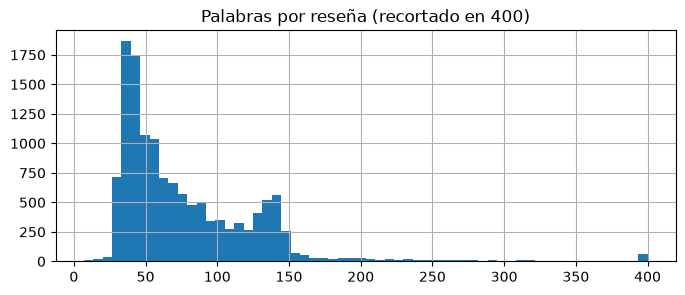

In [10]:
r = r.assign(n_palabras=r.review_text.str.split().str.len(), n_tit=r.title.str.split().str.len())
print(r.n_palabras.quantile([.5, .75, .9, .95, .99]).to_string())
print('\nMediana de palabras por etiqueta:', r.groupby('label').n_palabras.median().to_dict())
r.n_palabras.clip(upper=400).hist(bins=60, figsize=(8, 3)); plt.title('Palabras por reseña (recortado en 400)'); plt.show()

**Qué encontramos:** la mediana es 61 palabras, el p95 149 y el máximo supera las 1.400. Las **negativas son mucho más largas** (mediana 98, frente a 54 en las positivas): quien se queja explica más. Esto afecta a las redes recurrentes: con una secuencia más corta se cortan sobre todo quejas. Por eso `SEQ_LEN` se fija en el p95 de train (sección 6) y el truncamiento se mide como causa de error (sección 9).

#### 1.5 Ruido de superficie, PII e idioma

In [11]:
t = r.review_text
patrones = {
    'cortado en la fuente (termina en "…")': r'…\s*$',
    'signos "!!"': r'!!', 'puntos "..."': r'\.\.\.',
    'emoji': '[\U0001F300-\U0001FAFF\u2600-\u27BF]',
    'URL': r'https?://|www\.', 'correo real (usuario@dominio.xx)': r'[\w.%-]+@[\w.-]+\.[A-Za-z]{2,}',
    '"@" inclusivo (chic@s, tod@s)': r'\w@s?\b',
    'palabras en inglés (the/and/was)': r'\b(?:the|and|was|very)\b',
    'mayúsculas sostenidas (≥3 palabras)': r'(?:\b[A-ZÁÉÍÓÚÑ]{3,}\b\W+){3,}',
}
ruido = pd.Series({k: t.str.contains(p, regex=True).mean() for k, p in patrones.items()}).mul(100).round(2)
display(ruido.to_frame('% de reseñas'))
print('Textos que cambian con NFC:', (t != t.map(lambda s: unicodedata.normalize('NFC', s))).sum())
no_ascii = pd.Series([c for x in t for c in x if ord(c) > 127]).value_counts()
print('Caracteres no ASCII más frecuentes:', no_ascii.head(25).to_dict())
print('Títulos repetidos:', f'{r.title.duplicated().mean():.1%}', '| más comunes:', r.title.value_counts().head(5).to_dict())

,% de reseñas
"cortado en la fuente (termina en ""…"")",10.79
"signos ""!!""",6.20
"puntos ""...""",13.85
emoji,1.04
URL,0.01
correo real (usuario@dominio.xx),0.00
"""@"" inclusivo (chic@s, tod@s)",0.29
palabras en inglés (the/and/was),0.62
mayúsculas sostenidas (≥3 palabras),0.82


Textos que cambian con NFC: 2
Caracteres no ASCII más frecuentes: {'ó': 29504, 'í': 19546, 'á': 15514, 'ñ': 10314, 'é': 8777, 'ú': 4047, '…': 1623, '€': 697, '¡': 414, '“': 131, '¿': 131, '”': 126, 'ü': 122, 'о': 119, 'à': 108, 'а': 108, 'è': 103, '’': 102, 'е': 89, 'º': 82, 'н': 81, 'т': 80, 'Á': 78, 'Í': 69, 'ª': 65}
Títulos repetidos: 23.0% | más comunes: {'Excelente': 186, 'Perfecto': 88, 'Muy recomendable': 70, 'Recomendable': 55, 'Buen hotel': 51}


**Qué encontramos y qué decidimos:**
- **10,8 % de reseñas cortadas en la fuente** (terminan en "…"): el scraping no trajo el texto completo. No se puede recuperar. Se marca con `cortado_fuente` y se mide en el análisis de errores.
- **PII casi inexistente:** 0 correos reales y 0,01 % de URL. Los "@" son lenguaje inclusivo ("chic@s", "tod@s"), así que el enmascarado de correos se escribe para **no** tocarlos.
- **Otros idiomas (< 1 %):** 0,6 % con palabras en inglés y caracteres cirílicos (о, а, е, н, т). Hay pocos, pero el análisis de errores muestra que producen errores con confianza alta.
- **Codificación limpia:** solo 2 textos cambian con NFC y no hay mojibake. Los caracteres especiales son tildes, ñ, "…", "€", "¡" y "¿".
- **Énfasis:** "!!" (6,2 %), "..." (13,9 %), mayúsculas sostenidas (0,8 %) y emoji (1 %). Se conservan porque llevan sentimiento ("HORRIBLE!!!").
- **Títulos:** el 23 % se repite ("Excelente", "Perfecto", "Muy recomendable"). Son un resumen del sentimiento y se prueba concatenarlos a la reseña (A/B en 4.1).

#### 1.6 Backlog de preprocesamiento (entregable de la auditoría)

| # | Hallazgo | Decisión | ¿Antes o después del split? | Cómo se verifica |
|---|---|---|---|---|
| 1 | `rating` determina la etiqueta | Eliminar `rating` | Antes | Tabla cruzada 1.1 |
| 2 | 26,6 % de duplicados exactos | Deduplicar por título + texto | **Antes** (si no, hay fuga) | 0 % de claves de test en train (sección 3) |
| 3 | 13 % sin hotel, de otra fuente | Conservar; grupo propio en la partición | Antes | Resultado aparte en la sección 10 |
| 4 | 10,8 % cortadas en la fuente | Conservar y marcar `cortado_fuente` | Antes | Lift en el análisis de errores |
| 5 | Título informativo | Concatenar título + reseña | Antes | A/B 4.1 |
| 6 | URL y correos casi nulos; "@" inclusivo | Enmascarar URL y correos reales sin tocar "chic@s" | Antes | Regex de la sección 2 |
| 7 | Mayúsculas y tildes variables | Probar minúsculas y quitar tildes | Dentro del vectorizador (train) | A/B 4.1 |
| 8 | Stopwords incluyen "no", "ni", "nada" | Probar quitar stopwords | Dentro del vectorizador (train) | A/B 4.1 |
| 9 | Desbalance 72 / 15 / 13 | `class_weight='balanced'` | Pesos calculados con train | A/B 4.1 |
| 10 | Reseñas largas (p95 = 149); las negativas aún más | `SEQ_LEN` = p95 de train (153) y prueba con p95 de negativas (252) | **Después** (se calcula con train) | % truncadas **por clase** (6.1) y recall de negativas (7.2) |
| 11 | < 1 % en otros idiomas | Conservar en el experimento; en producción, detector de idioma | — | Error y confianza por idioma (10.2) |

## 2. Limpieza, normalización y lematización
Se aplican solo las transformaciones **que no aprenden de los datos**: deduplicar, descartar `rating`, normalizar Unicode y espacios y enmascarar URL y correos reales. El texto original se conserva y la versión transformada va en otra columna.

In [12]:
def normalizar(s):
    s = unicodedata.normalize('NFC', str(s))
    s = re.sub(r'https?://\S+|www\.\S+', ' URL ', s)
    s = re.sub(r'[\w.%-]+@[\w.-]+\.[A-Za-z]{2,}', ' EMAIL ', s)   # no toca "chic@s"
    return re.sub(r'\s+', ' ', s).strip()

ETQ = {0: 'negativa', 3: 'neutra', 1: 'positiva'}
df = (raw.drop_duplicates(['title', 'review_text'])          # 1) quitar duplicados ANTES del split
         .drop(columns='rating')                              # 2) rating = etiqueta: se elimina
         .reset_index(drop=True))
df['etiqueta'] = df.label.map(ETQ)
df['cortado_fuente'] = df.review_text.str.contains(r'…\s*$')
df['sin_hotel'] = df.hotel.isna()
df['texto_original'] = df.title + '. ' + df.review_text
df['texto'] = df.texto_original.map(normalizar)
df['solo_resena'] = df.review_text.map(normalizar)
print(df.shape); print(df.etiqueta.value_counts(normalize=True).round(3).to_dict())

(13331, 11)
{'positiva': 0.715, 'negativa': 0.154, 'neutra': 0.131}


**Por qué así:** el texto original queda en `texto_original` para auditoría y la versión transformada vive en `texto`. Igual que en la Sesión 2, aquí **no** se pasa a minúsculas ni se quitan signos. Esas decisiones las toma cada vectorizador y se prueban en A/B.

In [13]:
# Lematización con spaCy (modelo preentrenado: no ve nuestras etiquetas, así que se puede aplicar antes del split)
import spacy
nlp = spacy.load('es_core_news_sm', disable=['parser', 'ner'])
t0 = time.perf_counter()
df['lemas'] = [' '.join(tok.lemma_.lower() for tok in d if not tok.is_space)
               for d in nlp.pipe(df.texto, batch_size=256)]
print(f'Lematización: {time.perf_counter()-t0:.0f} s')
for o, l in df[['texto', 'lemas']].head(2).values: print('·', o[:110], '\n→', l[:110])

Lematización: 27 s
· Excelente y personal amable. Un hotel muy bueno. El personal fue muy amable y profesional. Nos gustaban desayu 
→ excelente y personal amable . uno hotel mucho bueno . el personal ser mucho amable y profesional . yo gustar d
· Céntrico. Muy buen hotel al nivel de lo esperado, habitación junior suite, no muy grande pero con todo lo dese 
→ céntrico . mucho buen hotel al nivel de él esperado , habitación junior suite , no mucho grande pero con todo 


**Qué encontramos:** spaCy lematiza las 13.331 reseñas en unos 24 s. Une variantes ("gustaban" → gustar) pero también comete errores típicos: "muy" → **"mucho"**, "Un" → "uno" y "Nos" → "yo". No arruinan la señal de sentimiento, pero muestran que el lematizador es un modelo con errores propios.

## 3. Partición sin fuga: por hotel (= por sede)
En el caso Bodytech la pregunta de negocio es: *¿funciona el modelo en una sede que nunca vio?* (una sede nueva o una ciudad nueva). Las reseñas nombran al hotel o sede, a su personal ("Juan de recepción") y sus calles. Si el mismo hotel aparece en train y en test, el modelo puede acertar por memoria del hotel y no por el sentimiento. Por eso se usa `StratifiedGroupKFold` con el **hotel como grupo**: cada hotel queda entero en train, en validación o en test. Las reseñas sin hotel forman cada una su propio grupo. La partición es 64 / 16 / 20.

In [14]:
grupos = df.hotel.fillna(pd.Series('sinhotel_' + df.index.astype(str), index=df.index))
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_trv, idx_te = next(sgkf.split(df, df.etiqueta, grupos))
sgkf2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
sub = df.iloc[idx_trv]
i_tr, i_va = next(sgkf2.split(sub, sub.etiqueta, grupos.iloc[idx_trv]))
idx_tr, idx_va = idx_trv[i_tr], idx_trv[i_va]
tr, va, te = df.iloc[idx_tr], df.iloc[idx_va], df.iloc[idx_te]
print('Tamaños:', len(tr), len(va), len(te))
print('Hoteles compartidos train∩test:', len(set(tr.hotel.dropna()) & set(te.hotel.dropna())),
      '| train∩val:', len(set(tr.hotel.dropna()) & set(va.hotel.dropna())))
display(pd.DataFrame({n: s.etiqueta.value_counts(normalize=True) for n, s in [('train', tr), ('val', va), ('test', te)]}).round(3))
CLASES = sorted(df.etiqueta.unique()); CRIT = 'negativa'
clave_df = df.review_text.map(plantilla)
# La partición se guarda para que cualquier modelo (o la demo) use exactamente los mismos índices
particion = pd.Series('train', index=df.index); particion.iloc[idx_va] = 'val'; particion.iloc[idx_te] = 'test'
pd.DataFrame({'particion': particion, 'grupo_sede': grupos, 'etiqueta': df.etiqueta}).to_csv(DATOS + 'particion.csv', index_label='id')
print(f'Textos de test con la misma clave de plantilla en train: {clave_df.iloc[idx_te].isin(set(clave_df.iloc[idx_tr])).mean():.2%}')

Tamaños: 8528 2132 2671
Hoteles compartidos train∩test: 0 | train∩val: 0


,train,val,test
etiqueta,,,
positiva,0.716,0.716,0.715
negativa,0.154,0.154,0.154
neutra,0.131,0.130,0.131


Textos de test con la misma clave de plantilla en train: 0.00%


**Qué encontramos:** 8.528 / 2.132 / 2.671 reseñas, **0 hoteles compartidos** entre particiones y proporciones de clase idénticas (72 / 15 / 13) en las tres, así que la estratificación por grupos funcionó. Además, **0 % de los textos de test tiene una clave de plantilla presente en train** (en la Sesión 2 era el 91 %).

#### 3.1 ¿Cuánto cambia la partición? Aleatoria frente a por hotel
Mismo modelo (TF-IDF de palabras + regresión logística) con las dos particiones. **Para no tocar test**, la comparación se hace dentro de train + validación: aleatoria (80/20 dentro de train + val) frente a por hotel (train → val).

In [15]:
def metricas(y_true, prob, clases=CLASES):
    y_true = np.asarray(y_true); pred = np.asarray(clases)[prob.argmax(1)]
    return {'f1_macro': f1_score(y_true, pred, average='macro'),
            'recall_negativa': recall_score(y_true, pred, labels=[CRIT], average='macro'),
            'f1_neutra': f1_score(y_true, pred, labels=['neutra'], average='macro'),
            'log_loss': log_loss(y_true, prob, labels=clases)}

def pipe_tfidf(**kw):
    return Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True, **kw)),
                     ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', C=4, random_state=SEED))])

trv = pd.concat([tr, va])   # test queda fuera
Xa_tr, Xa_va, ya_tr, ya_va = train_test_split(trv.texto, trv.etiqueta, test_size=len(va) / len(trv),
                                              random_state=SEED, stratify=trv.etiqueta)
p_rand = pipe_tfidf(ngram_range=(1, 2), min_df=2).fit(Xa_tr, ya_tr)
p_hot = pipe_tfidf(ngram_range=(1, 2), min_df=2).fit(tr.texto, tr.etiqueta)
display(pd.DataFrame({'aleatoria (dentro de train + val)': metricas(ya_va, p_rand.predict_proba(Xa_va)),
                      'por hotel (train → val)': metricas(va.etiqueta, p_hot.predict_proba(va.texto))}).round(3))

,aleatoria (dentro de train + val),por hotel (train → val)
f1_macro,0.763,0.753
recall_negativa,0.845,0.851
f1_neutra,0.541,0.499
log_loss,0.368,0.373


**Qué encontramos (en validación, sin tocar test):** con partición aleatoria el F1 macro es 0,763 y con partición por hotel 0,753. **La memoria del hotel infla apenas 0,01.** En la sesión 2 la diferencia era de 1,00 a 0,42 porque los textos se repetían; aquí cada reseña es una redacción nueva. Igual se mantiene la partición por hotel: responde la pregunta de negocio de Bodytech (*¿funciona en una sede nueva?*) y es la más exigente.

#### 3.2 ¿Cuánto inflarían los duplicados?
Se repite la partición aleatoria con el corpus **antes** y **después** de deduplicar, **sin usar las reseñas de test**.

In [16]:
claves_te = set(zip(te.title, te.review_text))
raw_sin_te = raw[[k not in claves_te for k in zip(raw.title, raw.review_text)]]   # se excluyen todas las copias de test
filas = []
for nombre, d in [(f'con duplicados ({len(raw_sin_te):,})', raw_sin_te.assign(texto=(raw_sin_te.title + '. ' + raw_sin_te.review_text).map(normalizar), etiqueta=raw_sin_te.label.map(ETQ))),
                  (f'sin duplicados ({len(tr) + len(va):,})', pd.concat([tr, va]))]:
    Xa, Xb, ya, yb = train_test_split(d.texto, d.etiqueta, test_size=.2, random_state=SEED, stratify=d.etiqueta)
    p = pipe_tfidf(ngram_range=(1, 2), min_df=2).fit(Xa, ya)
    filas.append({'corpus': nombre, '% de test idéntico a train': Xb.isin(set(Xa)).mean() * 100, **metricas(yb, p.predict_proba(Xb))})
display(pd.DataFrame(filas).set_index('corpus').round(3))

,% de test idéntico a train,f1_macro,recall_negativa,f1_neutra,log_loss
corpus,,,,,
"con duplicados (14,379)",37.656,0.837,0.881,0.683,0.271
"sin duplicados (10,660)",0.000,0.763,0.845,0.541,0.368


**Qué encontramos:** sin deduplicar, el **37,7 % de las reseñas de evaluación es idéntico a una de entrenamiento** y el F1 macro sube de **0,763 a 0,837** (+0,07). El recall de negativas pasa de 0,845 a 0,881. Si no se hubieran quitado las copias, habríamos reportado un modelo bastante mejor de lo que es.

## 4. Baseline: torneo disperso TF-IDF + regresión logística
Todas las configuraciones usan el mismo clasificador (regresión logística balanceada, `C=4`), la misma partición y se comparan **solo en validación**. Las probabilidades de test se calculan y se guardan para la sección 9, pero no se muestran.

In [17]:
configs = {
    'TF-IDF palabras (1-2)':   ('texto', dict(ngram_range=(1, 2), min_df=2)),
    'TF-IDF caracteres (3-5)': ('texto', dict(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=300_000)),
    'TF-IDF lemas (1-2)':      ('lemas', dict(ngram_range=(1, 2), min_df=2)),
}
torneo, modelos_tfidf, probs_te = [], {}, {}
for nombre, (col, kw) in configs.items():
    t0 = time.perf_counter(); p = pipe_tfidf(**kw).fit(tr[col], tr.etiqueta); seg = time.perf_counter() - t0
    mv, mt = metricas(va.etiqueta, p.predict_proba(va[col])), metricas(te.etiqueta, p.predict_proba(te[col]))
    probs_te[nombre] = p.predict_proba(te[col]); modelos_tfidf[nombre] = p
    torneo.append({'modelo': nombre, **{k + '_val': v for k, v in mv.items()},   # test: guardado, no se muestra
                   'vocabulario': len(p.named_steps['tfidf'].vocabulary_), 'seg_entreno': seg})
torneo = pd.DataFrame(torneo).set_index('modelo'); display(torneo.round(3))

,f1_macro_val,recall_negativa_val,f1_neutra_val,log_loss_val,vocabulario,seg_entreno
modelo,,,,,,
TF-IDF palabras (1-2),0.753,0.851,0.499,0.373,67058,1.368
TF-IDF caracteres (3-5),0.747,0.841,0.502,0.395,55572,4.834
TF-IDF lemas (1-2),0.760,0.863,0.514,0.364,57048,0.896


**Qué encontramos (validación):**

| | Palabras | Caracteres | **Lemas** |
|---|---|---|---|
| F1 macro | 0,753 | 0,747 | **0,760** |
| Recall negativa | 0,851 | 0,841 | **0,863** |
| F1 neutra | 0,499 | 0,502 | **0,514** |
| Log loss | 0,373 | 0,395 | **0,364** |

- **Gana TF-IDF de lemas** en todas las métricas, aunque las diferencias son pequeñas (≈ 0,01). Es el **baseline** del proyecto.
- **Caracteres pasa de ganador (sesión 2) a último:** aquí el texto es largo, la ortografía es razonable y la señal está en palabras completas de sentimiento.
- La clase **neutra** es la más difícil en las tres representaciones (F1 ≈ 0,50).

#### 4.1 Pruebas A/B del backlog (una decisión a la vez, medidas en validación)

In [18]:
from spacy.lang.es.stop_words import STOP_WORDS
W = dict(ngram_range=(1, 2), min_df=2)
ab = {
    'base (título + reseña, palabras 1-2)':      ('texto', W, 'balanced'),
    'sin título (solo reseña)':                  ('solo_resena', W, 'balanced'),
    'sin pasar a minúsculas':                    ('texto', {**W, 'lowercase': False}, 'balanced'),
    'quitar tildes':                             ('texto', {**W, 'strip_accents': 'unicode'}, 'balanced'),
    'quitar stopwords spaCy (incluye "no")':     ('texto', {**W, 'stop_words': list(STOP_WORDS)}, 'balanced'),
    'sin class_weight (no balancear)':           ('texto', W, None),
}
filas = []
for nombre, (col, kw, cw) in ab.items():
    p = Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True, **kw)),
                  ('clf', LogisticRegression(max_iter=2000, class_weight=cw, C=4, random_state=SEED))]).fit(tr[col], tr.etiqueta)
    filas.append({'prueba': nombre, **metricas(va.etiqueta, p.predict_proba(va[col]))})
ab_res = pd.DataFrame(filas).set_index('prueba'); display(ab_res.round(3))

,f1_macro,recall_negativa,f1_neutra,log_loss
prueba,,,,
"base (título + reseña, palabras 1-2)",0.753,0.851,0.499,0.373
sin título (solo reseña),0.724,0.857,0.436,0.411
sin pasar a minúsculas,0.750,0.854,0.499,0.385
quitar tildes,0.754,0.854,0.497,0.372
"quitar stopwords spaCy (incluye ""no"")",0.736,0.832,0.458,0.397
sin class_weight (no balancear),0.710,0.829,0.355,0.355


**Qué encontramos y qué decidimos (fila por fila):**
- **Título:** quitarlo baja el F1 macro de 0,753 a 0,724 y el F1 neutra de 0,50 a 0,44. El título es un resumen del sentimiento ("Correcto", "Mejorable"). **Se conserva.** *Limitación para Bodytech:* si las reseñas de la app o de Google no traen título, el desempeño real será menor (en esta prueba, 0,724 en vez de 0,753).
- **Minúsculas y tildes:** cambios ≤ 0,003, dentro del ruido. Se deja el valor por defecto (minúsculas, con tildes).
- **Quitar stopwords:** baja a 0,736 y el recall de negativas a 0,832, porque la lista de spaCy incluye "no", "ni", "nada" y "pero", que son justo las palabras que cambian el sentimiento. **No se quitan stopwords.**
- **No balancear:** el F1 neutra cae de 0,50 a 0,36 y el macro a 0,710, aunque el log loss mejora (0,355), porque sin pesos el modelo se inclina hacia "positiva" y queda mejor calibrado para la clase mayoritaria. Como la métrica prerregistrada es F1 macro, **se mantiene `class_weight='balanced'`**.

#### 4.2 Interpretabilidad del mejor modelo disperso

In [19]:
champ_tfidf = torneo.f1_macro_val.idxmax(); print('Campeón disperso (por validación):', champ_tfidf)
pw = modelos_tfidf['TF-IDF palabras (1-2)']   # se muestran palabras: son más legibles que n-gramas de caracteres
vocab = np.array(pw.named_steps['tfidf'].get_feature_names_out()); coefs = pw.named_steps['clf'].coef_
display(pd.DataFrame({c: vocab[np.argsort(coefs[i])[::-1][:12]] for i, c in enumerate(pw.named_steps['clf'].classes_)}))

Campeón disperso (por validación): TF-IDF lemas (1-2)


,negativa,neutra,positiva
0,no,normal,excelente
1,mala,pero,muy
2,peor,bien,perfecto
3,ni,aceptable,buen
4,pésimo,necesita,recomendable
5,viejo,normalito,muy bien
6,horrible,correcto,genial
7,mal,bastante,todo
8,decepcionante,sí,gracias
9,que,mejorable,limpio


**Qué encontramos:** los términos más pesados tienen sentido de negocio y no aparecen señales espurias (ni nombres de hoteles ni ciudades):
- **Negativa:** "no", "mala", "peor", "ni", "pésimo", "horrible", "decepcionante", "lamentable".
- **Neutra:** "normal", **"pero"**, "aceptable", "necesita", "normalito", "correcto", "mejorable". La clase neutra se define por el **contraste** y la tibieza, que es justo lo que más le cuesta a todos los modelos.
- **Positiva:** "excelente", "perfecto", "recomendable", "genial", "limpio" y "casa" (de "como en casa").

Para Bodytech la lista es reutilizable como guía: "mejorable", "necesita" y "pero" marcan reseñas tibias que conviene revisar antes de que se vuelvan cancelaciones.

## 5. Embeddings Word2Vec y fastText (entrenados solo con train)
En la Sesión 2 el corpus auxiliar de embeddings filtraba las etiquetas. Aquí no hay corpus auxiliar, así que los vectores se entrenan **solo con las reseñas de train**.

In [20]:
from gensim.models import Word2Vec, FastText
def tokenizar(s): return re.sub(r'[^\wáéíóúñü\s]', ' ', s.lower()).split()
tok_tr, tok_va, tok_te = [list(map(tokenizar, s.texto)) for s in (tr, va, te)]
import sys
# workers=1: con varios hilos gensim NO es reproducible aunque tenga semilla (el orden de los hilos cambia el resultado)
# El hook silencia los avisos internos "Exception ignored in our_dot_float" de gensim, que no afectan el resultado
_hook = sys.unraisablehook; sys.unraisablehook = lambda *_: None
t0 = time.perf_counter()
w2v = Word2Vec(tok_tr, vector_size=100, window=5, min_count=2, workers=1, epochs=10, seed=SEED)
ftx = FastText(tok_tr, vector_size=100, window=5, min_count=2, workers=1, epochs=10, seed=SEED)
sys.unraisablehook = _hook
print(f'Entrenamiento de ambos: {time.perf_counter()-t0:.0f} s | vocabulario: {len(w2v.wv)}')
for w in ['limpio', 'sucio', 'ruido', 'desayuno', 'amable', 'horrible']:
    print(f'{w:>9} · w2v:', [x for x, _ in w2v.wv.most_similar(w, topn=5)], '| ftx:', [x for x, _ in ftx.wv.most_similar(w, topn=5)])

Entrenamiento de ambos: 19 s | vocabulario: 12933
   limpio · w2v: ['silencioso', 'moderno', 'funcional', 'nuevo', 'comodo'] | ftx: ['limpito', 'superlimpio', 'limpisimo', 'limpió', 'pimpi']
    sucio · w2v: ['roto', 'viejo', 'descuidado', 'huele', 'estropeadas'] | ftx: ['mobiliario', 'inmobiliario', 'armario', 'basilio', 'roto']
    ruido · w2v: ['pasillo', 'suelo', 'ruidos', 'ruidosa', 'jaleo'] | ftx: ['construido', 'ruidoso', 'descuido', 'ruidosa', 'ruidito']
 desayuno · w2v: ['buffet', 'bufet', 'variado', 'servicio', 'menú'] | ftx: ['desayune', 'desayuna', 'desayunador', 'desyuno', 'desayunaba']
   amable · w2v: ['atento', 'agradable', 'amabilísimo', 'simpático', 'profesional'] | ftx: ['superamable', 'infumable', 'amablemente', 'agradable', 'amabilísimo']
 horrible · w2v: ['pésimo', 'deficiente', 'fatal', 'indescriptible', 'deprimente'] | ftx: ['insufrible', 'asumible', 'flexible', 'exigible', 'noble']


**Qué encontramos:**
- **Word2Vec aprende significado:** "limpio" ≈ silencioso, moderno, funcional; "amable" ≈ atento, agradable, amabilísimo; "horrible" ≈ pésimo, deficiente, fatal.
- **fastText aprende forma:** recupera variantes y errores ortográficos ("limpito", "limpisimo", "desyuno", "superamable"), útil contra el OOV. Pero también produce **vecinos espurios por rima**: "horrible" ≈ asumible, flexible, exigible; "sucio" ≈ mobiliario, inmobiliario, basilio; "amable" ≈ **infumable** (¡lo contrario!). Comparte sub-palabras, no sentimiento.
- A diferencia de la Sesión 2 no hay fuga: los vectores se entrenaron solo con train.
- Se entrena con `workers=1`: con varios hilos gensim no es reproducible aunque tenga semilla, y los vecinos y el F1 cambiarían en cada ejecución.

In [21]:
def oov(tokens_docs, vocab):
    toks = [t for d in tokens_docs for t in d]; return np.mean([t not in vocab for t in toks])
print(f'OOV de tokens en validación: {oov(tok_va, w2v.wv.key_to_index):.1%}')

def doc_vec(m, docs, permitir_oov):
    out = np.zeros((len(docs), m.vector_size))
    for i, d in enumerate(docs):
        v = [m.wv[t] for t in d if permitir_oov or t in m.wv.key_to_index]
        if v: out[i] = np.mean(v, 0)
    return out
emb_rows = []
for nombre, m, po in [('Word2Vec promedio', w2v, False), ('fastText promedio', ftx, True)]:
    clf = LogisticRegression(max_iter=3000, class_weight='balanced', C=4, random_state=SEED).fit(doc_vec(m, tok_tr, po), tr.etiqueta)
    mv = metricas(va.etiqueta, clf.predict_proba(doc_vec(m, tok_va, po)))
    pt = clf.predict_proba(doc_vec(m, tok_te, po)); probs_te[nombre] = pt
    emb_rows.append({'modelo': nombre, **{k + '_val': v for k, v in mv.items()}})   # test: guardado, no se muestra
emb_res = pd.DataFrame(emb_rows).set_index('modelo'); display(emb_res.round(3))
print('Referencia: baseline TF-IDF de lemas en validación, F1 macro', round(torneo.loc['TF-IDF lemas (1-2)', 'f1_macro_val'], 3))

OOV de tokens en validación: 3.2%


,f1_macro_val,recall_negativa_val,f1_neutra_val,log_loss_val
modelo,,,,
Word2Vec promedio,0.710,0.820,0.477,0.513
fastText promedio,0.697,0.811,0.460,0.540


Referencia: baseline TF-IDF de lemas en validación, F1 macro 0.76


**Qué encontramos:** solo el **3,2 % de los tokens** de validación es OOV. Aun así, el vector promedio queda por debajo de TF-IDF (F1 macro de validación 0,710 con Word2Vec y 0,697 con fastText, frente a 0,760). **Promediar diluye la negación y el contraste**: "no estaba limpio" se parece a "estaba limpio" porque el promedio pierde el orden. Es la motivación de los modelos que leen la secuencia (secciones 7 y 8).

## 6. Tokenización secuencial: vocabulario, PAD, OOV, padding y truncamiento
`TextVectorization` aprende el vocabulario **solo con train**. El índice 0 es PAD, el 1 es OOV (`[UNK]`) y desde el 2 van las palabras de train por frecuencia. La longitud de secuencia (`SEQ_LEN`) se fija en el **percentil 95 de train**: corta menos del 5 % de las reseñas sin llenar las secuencias de PAD.

In [22]:
le = LabelEncoder().fit(CLASES)
ytr_i, yva_i, yte_i = (le.transform(s.etiqueta) for s in (tr, va, te))
long_tr = tr.texto.map(lambda s: len(tokenizar(s)))
SEQ_LEN = int(np.percentile(long_tr, 95)); MAX_TOKENS = 20000; EMBED_DIM = 64
tv = tf.keras.layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode='int', output_sequence_length=SEQ_LEN,
                                       standardize='lower_and_strip_punctuation')
tv.adapt(tf.data.Dataset.from_tensor_slices(tr.texto.values).batch(256))
Xtr_s, Xva_s, Xte_s = (tv(s.texto.values).numpy() for s in (tr, va, te))
voc = tv.get_vocabulary()
print('SEQ_LEN:', SEQ_LEN, '| vocabulario:', len(voc), '| primeros índices:', voc[:6])
def resumen_seq(X, textos):
    largos = textos.map(lambda s: len(tokenizar(s)))
    return {'% truncadas': (largos > SEQ_LEN).mean(), '% posiciones PAD': (X == 0).mean(),
            '% tokens OOV (sin PAD)': (X == 1).sum() / (X != 0).sum()}
display(pd.DataFrame({n: resumen_seq(X, s.texto) for n, X, s in [('train', Xtr_s, tr), ('val', Xva_s, va)]}).mul(100).round(2))
print('Ejemplo →', va.texto.iloc[0][:80], '\n', Xva_s[0][:20])

SEQ_LEN: 153 | vocabulario: 20000 | primeros índices: ['', '[UNK]', np.str_('de'), np.str_('y'), np.str_('la'), np.str_('el')]


,train,val
% truncadas,4.85,5.82
% posiciones PAD,49.26,49.06
% tokens OOV (sin PAD),1.53,3.30


Ejemplo → A great hotel for a long weekend in Sevilla.. amazing rooftop.. Hotel muy bien u 
 [   9 2603   14 1531    9    1 6484  474   79 4309 4382   14    8   28
  153   16 1944   79    8  142]


**Qué encontramos:**
- `SEQ_LEN = 153` (p95 de train): se truncan el 4,9 % de train y el 5,8 % de validación. **Pero ese promedio esconde que se corta el 15 % de las negativas**, la clase crítica (6.1).
- **El 49 % de las posiciones son PAD.** Sin `mask_zero=True` la red "leería" la mitad de su entrada como ceros; con la máscara las ignora.
- **OOV:** 1,5 % en train y **3,3 % en validación**. En train el OOV sale solo del tope de 20.000 palabras; en validación aparecen palabras nuevas (nombres de otros hoteles, errores de tipeo). Es la brecha que se verá en producción.

#### 6.0 ¿Por qué 20.000 palabras? OOV según el tamaño del vocabulario
El embedding es casi todo el modelo (95-97 % de los parámetros, según la red), así que el tamaño del vocabulario no es un detalle. Se mide el OOV **en validación** para varios topes: el vocabulario se ordena por frecuencia en train y cada tope se queda con las palabras más frecuentes.

In [23]:
tv_full = tf.keras.layers.TextVectorization(max_tokens=None, standardize='lower_and_strip_punctuation', ragged=True)
tv_full.adapt(tf.data.Dataset.from_tensor_slices(tr.texto.values).batch(256))
V_TOTAL = len(tv_full.get_vocabulary())
ids_tr, ids_va = (tv_full(s.texto.values).flat_values.numpy() for s in (tr, va))
ids_va_neg = tv_full(va.texto.values[(va.etiqueta == 'negativa').values]).flat_values.numpy()
frec = np.bincount(ids_tr, minlength=V_TOTAL)
resto_bilstm = 2 * 4 * (EMBED_DIM * 64 + 64 * 64 + 64) + 2 * 64 * len(CLASES) + len(CLASES)   # capas que no son embedding
pct_oov = lambda ids, k: ((ids >= k) | (ids == 1)).mean() * 100   # índice 1 = [UNK]
vocab_tab = pd.DataFrame([{'MAX_TOKENS': k, '% OOV train': pct_oov(ids_tr, k), '% OOV val': pct_oov(ids_va, k),
                           '% OOV val (negativas)': pct_oov(ids_va_neg, k), 'frecuencia mínima en train': int(frec[min(k, V_TOTAL) - 1]),
                           'parámetros embedding': k * EMBED_DIM, '% parámetros BiLSTM': 100 * k * EMBED_DIM / (k * EMBED_DIM + resto_bilstm)}
                          for k in [2000, 5000, 10000, 20000, V_TOTAL]]).set_index('MAX_TOKENS')
print('Vocabulario completo de train:', V_TOTAL, 'palabras')
display(vocab_tab.round(2))

Vocabulario completo de train: 31048 palabras


,% OOV train,% OOV val,% OOV val (negativas),frecuencia mínima en train,parámetros embedding,% parámetros BiLSTM
MAX_TOKENS,,,,,,
2000,11.85,12.38,16.05,25,128000,65.83
5000,6.26,6.99,9.62,7,320000,82.81
10000,3.48,4.51,6.28,2,640000,90.60
20000,1.58,3.39,4.77,1,1280000,95.07
31048,0.00,2.69,3.73,1,1987072,96.76


**Qué encontramos:** train tiene **31.048 palabras distintas**; el tope de 20.000 se había fijado sin medir.

| Tope de vocabulario | OOV val | OOV val (negativas) | Frecuencia mínima en train | Parámetros del embedding |
|---|---|---|---|---|
| 5.000 | 7,0 % | 9,6 % | 7 | 320 k |
| **10.000** | **4,5 %** | **6,3 %** | **2** | **640 k** |
| 20.000 | 3,4 % | 4,8 % | 1 | 1,28 M |
| 31.048 (todo) | 2,7 % | 3,7 % | 1 | 1,99 M |

- **De 10.000 a 20.000 se agregan palabras que aparecen una sola vez en train.** Cuestan 640 k parámetros más y solo bajan el OOV de validación de 4,5 % a 3,4 %. Una red no puede aprender un vector útil a partir de un único ejemplo.
- **10.000 es el corte natural:** son las palabras con frecuencia ≥ 2, el mismo criterio que `min_df=2` en TF-IDF y `min_count=2` en Word2Vec.
- **Por debajo de 5.000 el OOV se dispara** (7 %, y casi 10 % en las negativas).
- **Las negativas tienen más OOV** que el promedio en todos los topes: las quejas usan un vocabulario más variado (nombres de cosas que fallaron).
- **Decisión:** se mantiene 20.000 en el torneo principal para no cambiar todo el experimento, y en **7.3** se mide con la red si 10.000 rinde igual en validación.

#### 6.1 ¿A quién corta el truncamiento? (la guía pide < 5 % de casos críticos truncados)

In [24]:
long_va = va.texto.map(lambda s: len(tokenizar(s)))
trunc = pd.DataFrame({n: s.groupby(s.index.map(lambda i: df.etiqueta[i])).apply(lambda x: (x > SEQ_LEN).mean() * 100)
                      for n, s in [('train', long_tr), ('val', long_va)]}).round(1)
trunc.columns = [f'% truncadas con SEQ_LEN={SEQ_LEN} ({c})' for c in trunc.columns]
display(trunc)
SEQ_LEN_NEG = int(np.percentile(long_tr[tr.etiqueta == 'negativa'], 95))
print(f'p95 de las negativas en train: {SEQ_LEN_NEG} tokens → se prueba esa longitud en la sección 7.2')

,% truncadas con SEQ_LEN=153 (train),% truncadas con SEQ_LEN=153 (val)
negativa,15.2,18.6
neutra,6.7,6.8
positiva,2.3,2.9


p95 de las negativas en train: 252 tokens → se prueba esa longitud en la sección 7.2


**Qué encontramos (corrige lo dicho en la sección 6):** `SEQ_LEN = 153` trunca solo el 5 % del total, pero ese promedio esconde el problema: **trunca el 15 % de las negativas** (15,2 % en train y 18,6 % en validación), frente al 2,3 % de las positivas, porque las quejas son más largas. La guía pide **menos del 5 % de casos críticos truncados**, así que `SEQ_LEN = 153` **no cumple**. Para cumplirlo con las negativas hace falta el p95 de esa clase, **calculado en train: 252 tokens**. En la sección 7.2 se mide si eso mejora el modelo.

## 7. Torneo recurrente: SimpleRNN, LSTM, GRU y BiLSTM
Es la misma arquitectura de la Sesión 3 para que la comparación sea justa: `Embedding(mask_zero=True)` → capa recurrente de 64 unidades → Dropout → Softmax, con Adam, `clipnorm=1.0` (contra el gradiente explosivo), pesos de clase balanceados y early stopping en `val_loss`. La única diferencia entre modelos es la celda recurrente.

In [25]:
pesos = dict(enumerate(compute_class_weight('balanced', classes=np.arange(len(CLASES)), y=ytr_i)))
print('Pesos de clase:', {le.classes_[k]: round(v, 2) for k, v in pesos.items()})

def build_model(kind='lstm', units=64, dropout=.3, bidirectional=False, lr=1e-3):
    inp = tf.keras.Input((SEQ_LEN,), dtype='int64')
    x = tf.keras.layers.Embedding(len(voc), EMBED_DIM, mask_zero=True)(inp)
    cls = {'rnn': tf.keras.layers.SimpleRNN, 'lstm': tf.keras.layers.LSTM, 'gru': tf.keras.layers.GRU}[kind]
    rec = cls(units, dropout=dropout)
    x = tf.keras.layers.Bidirectional(rec)(x) if bidirectional else rec(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(len(CLASES), activation='softmax')(x)
    m = tf.keras.Model(inp, out, name=('bi' if bidirectional else '') + kind)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr, clipnorm=1.0), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def run(kind, bidirectional=False, epochs=15):
    tf.keras.utils.set_random_seed(SEED)
    m = build_model(kind, bidirectional=bidirectional)
    cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]
    t0 = time.perf_counter()
    h = m.fit(Xtr_s, ytr_i, validation_data=(Xva_s, yva_i), epochs=epochs, batch_size=64,
              class_weight=pesos, verbose=0, callbacks=cb)
    seg = time.perf_counter() - t0
    pva, pte = m.predict(Xva_s, verbose=0), m.predict(Xte_s, verbose=0)
    print(f'{m.name:>7}: {len(h.history["loss"])} épocas, {seg:.0f} s')
    return m, h, pva, pte, seg
build_model('lstm').summary()

Pesos de clase: {np.str_('negativa'): np.float64(2.17), np.str_('neutra'): np.float64(2.55), np.str_('positiva'): np.float64(0.47)}


Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 153)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 153, 64)   │  1,280,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 153)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 3)         │        195 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,313,219 (5.01 MB)

 Trainable params: 1,313,219 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
artefactos = {}
for kind, bi in [('rnn', False), ('lstm', False), ('gru', False), ('lstm', True)]:
    m, h, pva, pte, seg = run(kind, bi)
    artefactos[m.name] = dict(modelo=m, hist=h, prob_va=pva, prob_te=pte, seg=seg)

    rnn: 6 épocas, 19 s


   lstm: 8 épocas, 48 s


    gru: 5 épocas, 31 s


 bilstm: 6 épocas, 52 s


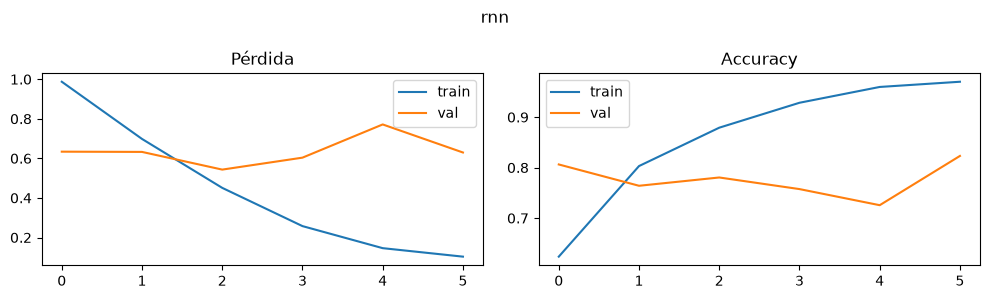

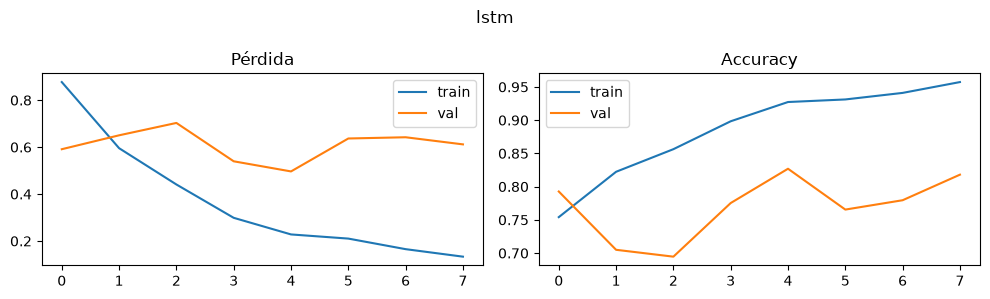

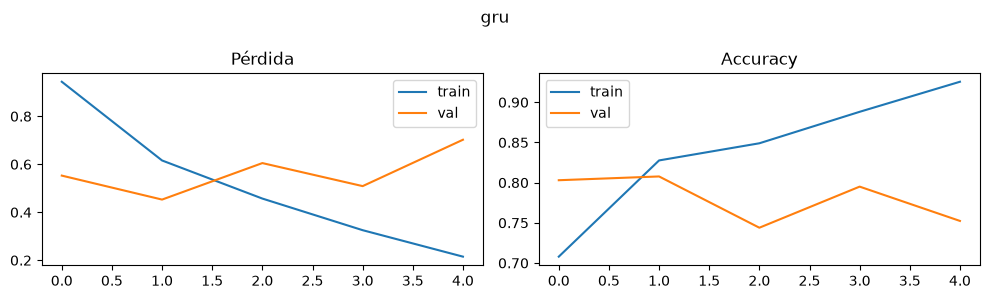

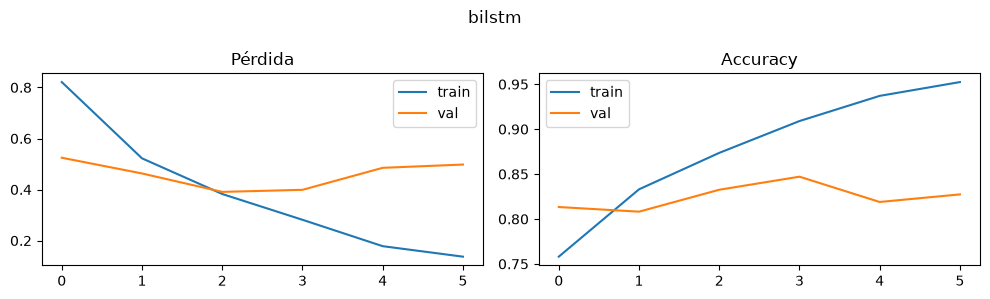

In [27]:
def plot_history(h, title):
    hh = pd.DataFrame(h.history); fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(hh.loss, label='train'); ax[0].plot(hh.val_loss, label='val'); ax[0].set_title('Pérdida'); ax[0].legend()
    ax[1].plot(hh.accuracy, label='train'); ax[1].plot(hh.val_accuracy, label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()
for n, a in artefactos.items(): plot_history(a['hist'], n)

**Qué encontramos:** los cuatro modelos se detienen pronto (5 a 8 épocas con paciencia 3, es decir, su mejor `val_loss` llega entre la época 2 y la 5). La pérdida de train sigue bajando mientras la de validación sube: es **sobreajuste rápido**. Con 8.528 reseñas, la red debe aprender desde cero un embedding de 20.000 × 64 = 1,28 M de parámetros (el 97 % del modelo), y no hay datos suficientes para hacerlo bien. En 7.3 se prueba si reducir o preentrenar el embedding lo corrige.

#### 7.1 ¿El orden entre redes depende de la semilla?
Una sola semilla puede dar un orden engañoso entre arquitecturas (la guía lo marca como señal de inestabilidad). Se repite el entrenamiento con **5 semillas** por red. Se agrega una **LSTM que lee la reseña al revés** (`go_backwards=True`) para probar *dónde* está la información: si leer al revés mejora a la LSTM, lo decisivo está al **inicio** del texto (el título), porque es lo último que lee y lo que más pesa en su estado final.

**Regla de método:** en 7.1, 7.2 y 7.3 **se decide solo con validación**. Las métricas de test se calculan y se guardan, pero no se miran hasta la sección 9, cuando el modelo final ya está elegido. Los entrenamientos largos se guardan en `modelos/cache/`.

In [28]:
def build_var(kind='lstm', seq_len=SEQ_LEN, bidirectional=False, go_backwards=False, units=64, dropout=.3, lr=1e-3,
              n_vocab=None, emb_matriz=None, emb_entrenable=True):
    inp = tf.keras.Input((seq_len,), dtype='int64')
    if emb_matriz is None:   # embedding aprendido desde cero
        x = tf.keras.layers.Embedding(n_vocab or len(voc), EMBED_DIM, mask_zero=True)(inp)
    else:                    # embedding iniciado con vectores preentrenados (7.3)
        x = tf.keras.layers.Embedding(*emb_matriz.shape, mask_zero=True, trainable=emb_entrenable,
                                      embeddings_initializer=tf.keras.initializers.Constant(emb_matriz))(inp)
    cls = {'rnn': tf.keras.layers.SimpleRNN, 'lstm': tf.keras.layers.LSTM, 'gru': tf.keras.layers.GRU}[kind]
    rec = cls(units, dropout=dropout, go_backwards=go_backwards)
    x = tf.keras.layers.Bidirectional(rec)(x) if bidirectional else rec(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    m = tf.keras.Model(inp, tf.keras.layers.Dense(len(CLASES), activation='softmax')(x))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr, clipnorm=1.0), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def entrenar_var(kind, seed, bidirectional=False, go_backwards=False, datos=None, seq_len=SEQ_LEN, **kw):
    """Métricas de validación (para DECIDIR) y de test (se guardan; solo se miran en la sección 9)."""
    Xa, Xb, Xc = datos if datos is not None else (Xtr_s, Xva_s, Xte_s)
    tf.keras.utils.set_random_seed(seed)
    m = build_var(kind, seq_len, bidirectional, go_backwards, **kw)
    m.fit(Xa, ytr_i, validation_data=(Xb, yva_i), epochs=15, batch_size=64, class_weight=pesos, verbose=0,
          callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])
    pva, pte = m.predict(Xb, verbose=0), m.predict(Xc, verbose=0)
    r = {**{k + '_val': v for k, v in metricas(va.etiqueta, pva).items()},
         **{k + '_test': v for k, v in metricas(te.etiqueta, pte).items()}}
    return r, pva, pte

col_b = configs[champ_tfidf][0]
BASE_VAL = metricas(va.etiqueta, modelos_tfidf[champ_tfidf].predict_proba(va[col_b]))   # para decidir
BASE = metricas(te.etiqueta, probs_te[champ_tfidf])                                     # solo para la sección 9
SEMILLAS = [42, 7, 123, 2024, 99]
VARIANTES = [('SimpleRNN', 'rnn', False, False), ('LSTM', 'lstm', False, False), ('GRU', 'gru', False, False),
             ('BiLSTM', 'lstm', True, False), ('LSTM al revés', 'lstm', False, True)]
def _semillas():
    filas = []
    for nombre, kind, bi, back in VARIANTES:
        for sd in SEMILLAS:
            r, _, _ = entrenar_var(kind, sd, bi, back); filas.append({'modelo': nombre, 'semilla': sd, **r})
    return pd.DataFrame(filas)
t0 = time.perf_counter(); semillas = en_cache('rnn_semillas', _semillas)
print(f'{len(semillas)} entrenamientos ({(time.perf_counter() - t0) / 60:.1f} min en esta ejecución) · métricas de VALIDACIÓN')
resumen_sem = semillas.groupby('modelo', sort=False).agg(
    f1_media=('f1_macro_val', 'mean'), f1_desv=('f1_macro_val', 'std'), f1_min=('f1_macro_val', 'min'), f1_max=('f1_macro_val', 'max'),
    recall_neg_media=('recall_negativa_val', 'mean'), recall_neg_min=('recall_negativa_val', 'min'), f1_neutra_media=('f1_neutra_val', 'mean'))
display(resumen_sem.round(3))
print('Baseline TF-IDF lemas en validación (determinista): F1 macro', round(BASE_VAL['f1_macro'], 3),
      '| recall negativa', round(BASE_VAL['recall_negativa'], 3))
print('Corridas que superan al baseline en validación:', int((semillas.f1_macro_val > BASE_VAL['f1_macro']).sum()), 'de', len(semillas))

[caché] rnn_semillas: leído de ../modelos/cache/rnn_semillas.csv (REENTRENAR=1 para volver a entrenar)
25 entrenamientos (0.0 min en esta ejecución) · métricas de VALIDACIÓN


,f1_media,f1_desv,f1_min,f1_max,recall_neg_media,recall_neg_min,f1_neutra_media
modelo,,,,,,,
SimpleRNN,0.646,0.015,0.632,0.665,0.726,0.616,0.306
LSTM,0.694,0.024,0.654,0.716,0.797,0.628,0.383
GRU,0.700,0.018,0.676,0.719,0.732,0.649,0.422
BiLSTM,0.737,0.009,0.723,0.744,0.795,0.665,0.493
LSTM al revés,0.737,0.009,0.726,0.751,0.766,0.683,0.498


Baseline TF-IDF lemas en validación (determinista): F1 macro 0.76 | recall negativa 0.863
Corridas que superan al baseline en validación: 0 de 25


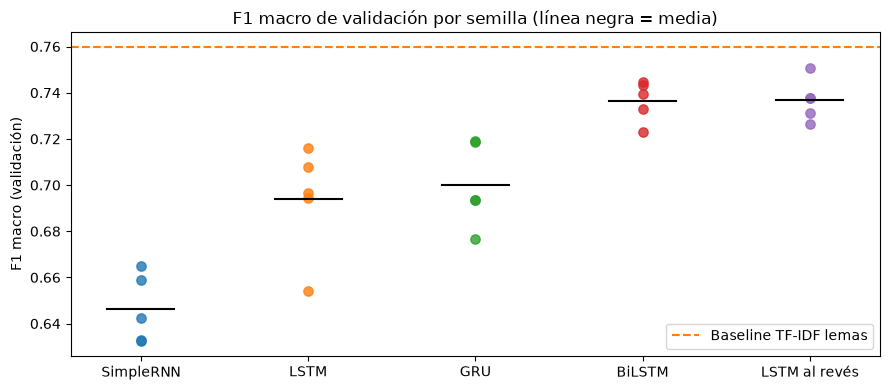

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = [v[0] for v in VARIANTES]
for i, n in enumerate(orden):
    v = semillas.loc[semillas.modelo == n, 'f1_macro_val']
    ax.scatter([i] * len(v), v, s=45, alpha=.8); ax.plot([i - .2, i + .2], [v.mean()] * 2, c='k')
ax.axhline(BASE_VAL['f1_macro'], ls='--', c='tab:orange', label='Baseline TF-IDF lemas')
ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden); ax.set_ylabel('F1 macro (validación)')
ax.set_title('F1 macro de validación por semilla (línea negra = media)'); ax.legend(); plt.tight_layout(); plt.show()

**Qué encontramos (5 semillas por red, 25 entrenamientos, métricas de validación):**

| | SimpleRNN | LSTM | GRU | BiLSTM | LSTM al revés | Baseline |
|---|---|---|---|---|---|---|
| F1 macro media | 0,646 | 0,694 | 0,700 | **0,737** | **0,737** | **0,760** |
| Rango (mín – máx) | 0,632 – 0,665 | 0,654 – 0,716 | 0,676 – 0,719 | 0,723 – 0,744 | 0,726 – 0,751 | determinista |
| Recall negativa media | 0,726 | 0,797 | 0,732 | 0,795 | 0,766 | 0,863 |

- **El orden entre LSTM y GRU no es confiable.** Con la semilla 42 GRU superaba a LSTM (tablero, 0,719 frente a 0,708 en validación), pero con 5 semillas sus medias son casi iguales (0,694 y 0,700) y sus rangos se cruzan. La LSTM va de 0,654 a 0,716 solo cambiando la semilla.
- **Lo que sí se sostiene:** SimpleRNN es la peor en todas las semillas (H2), y **ninguna de las 25 corridas supera al baseline en validación** (máximo 0,751 frente a 0,760), así que H1 sigue rechazada.
- **BiLSTM y la LSTM al revés son las más estables** (desviación 0,009).
- **¿Dónde está la información?** La **LSTM que lee al revés** (último token primero, título al final) sube de 0,694 a **0,737**, lo mismo que la BiLSTM. Si lo decisivo estuviera al final de la reseña, leer al revés empeoraría. Pasa lo contrario: lo más informativo está **al inicio, en el título**, que una LSTM normal "olvida" tras 150 pasos. Esto corrige la explicación que dimos antes ("la queja suele aparecer al final"), que no habíamos probado.
- **Decisión (en validación):** la **BiLSTM** es la red de referencia para 7.2 y 7.3. Empata en F1 con la LSTM al revés, pero detecta más negativas (0,795 frente a 0,766).

#### 7.2 ¿Y si no se cortan las negativas? (`SEQ_LEN` = p95 de las negativas)

In [30]:
tv_l = tf.keras.layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode='int', output_sequence_length=SEQ_LEN_NEG,
                                         standardize='lower_and_strip_punctuation', vocabulary=voc[2:])
XL = tuple(tv_l(s.texto.values).numpy() for s in (tr, va, te))
largas_neg_va = ((long_va > SEQ_LEN) & (va.etiqueta == 'negativa')).values
largas_neg_te = ((te.texto.map(lambda s: len(tokenizar(s))) > SEQ_LEN) & (te.etiqueta == 'negativa')).values   # se guarda para la sección 9
n_neg_va = (va.etiqueta == 'negativa').sum()
print(f'Negativas de validación truncadas: con {SEQ_LEN} → {largas_neg_va.sum()} ({largas_neg_va.sum() / n_neg_va:.1%}) | '
      f'con {SEQ_LEN_NEG} → {((long_va > SEQ_LEN_NEG) & (va.etiqueta == "negativa")).sum()}')
rec_largas = lambda p, mask: (np.asarray(CLASES)[p.argmax(1)][mask] == 'negativa').mean()
def _largo():
    filas = []
    for nombre, bi in [('LSTM', False), ('BiLSTM', True)]:
        for sd in SEMILLAS[:3]:
            for L, datos in [(SEQ_LEN, None), (SEQ_LEN_NEG, XL)]:
                r, pva, pte = entrenar_var('lstm', sd, bi, datos=datos, seq_len=L)
                filas.append({'modelo': nombre, 'SEQ_LEN': L, 'semilla': sd, **r,
                              'recall_negativas_largas_val': rec_largas(pva, largas_neg_va),
                              'recall_negativas_largas_test': rec_largas(pte, largas_neg_te)})
    return pd.DataFrame(filas)
largo = en_cache('rnn_longitud', _largo)
display(largo.groupby(['modelo', 'SEQ_LEN'])[['f1_macro_val', 'recall_negativa_val', 'recall_negativas_largas_val']].mean().round(3))

Negativas de validación truncadas: con 153 → 61 (18.6%) | con 252 → 20
[caché] rnn_longitud: leído de ../modelos/cache/rnn_longitud.csv (REENTRENAR=1 para volver a entrenar)


f1_macro_val  recall_negativa_val  recall_negativas_largas_val
modelo SEQ_LEN                                                                
BiLSTM 153             0.737                0.765                        0.847
       252             0.726                0.833                        0.885
LSTM   153             0.707                0.768                        0.825
       252             0.698                0.827                        0.907

**Qué encontramos (3 semillas por configuración, métricas de validación):**

| | F1 macro | Recall negativas | Recall negativas largas |
|---|---|---|---|
| BiLSTM · 153 | **0,737** | 0,765 | 0,847 |
| BiLSTM · 252 | 0,726 | **0,833** | **0,885** |
| LSTM · 153 | 0,707 | 0,768 | 0,825 |
| LSTM · 252 | 0,698 | **0,827** | **0,907** |

- Con 252 tokens las negativas truncadas en validación bajan de **61 (18,6 %) a 20**.
- El **recall de negativas sube unos 6 puntos** en las dos redes (BiLSTM 0,765 → 0,833), y más aún en las negativas largas. A cambio, el F1 macro baja alrededor de 0,01 y el entrenamiento es más lento (secuencias 65 % más largas).
- **Decisión (en validación):** para Bodytech la clase crítica es la negativa, así que **conviene la secuencia larga** (p95 de las negativas). Aun así, ninguna configuración alcanza el recall del baseline en validación (0,863), que no trunca nada.

#### 7.3 ¿Se puede frenar el sobreajuste del embedding? Vocabulario reducido e inicio con Word2Vec
El embedding aprendido desde cero tiene el 97 % de los parámetros y la red sobreajusta en pocas épocas. Se prueban dos remedios con la **BiLSTM** (la red más estable de 7.1), 3 semillas cada uno y **decisión en validación**:
- **Vocabulario de 10.000 palabras** en vez de 20.000 (mitad de parámetros del embedding; ver 6.0).
- **Iniciar el embedding con el Word2Vec de la sección 5** (entrenado solo con train, 100 dimensiones), **congelado** (no se entrena: quedan muy pocos parámetros libres) o **ajustable** (parte de Word2Vec y se sigue entrenando).

In [31]:
N_VOC_RED = 10000
tv_r = tf.keras.layers.TextVectorization(max_tokens=N_VOC_RED, output_mode='int', output_sequence_length=SEQ_LEN,
                                         standardize='lower_and_strip_punctuation', vocabulary=voc[2:N_VOC_RED])
XR = tuple(tv_r(s.texto.values).numpy() for s in (tr, va, te))
# Matriz de embedding alineada con el vocabulario de TextVectorization; palabras sin vector Word2Vec → aleatorio pequeño
rng_e = np.random.default_rng(SEED)
M_W2V = rng_e.normal(0, w2v.wv.vectors.std(), (len(voc), w2v.vector_size)).astype('float32'); M_W2V[0] = 0   # PAD = 0
con_vec = np.array([str(w) in w2v.wv.key_to_index for w in voc]); con_vec[:2] = False
M_W2V[con_vec] = np.stack([w2v.wv[str(w)] for w, ok in zip(voc, con_vec) if ok])
print(f'Vocabulario con vector Word2Vec: {con_vec[2:].mean():.1%} de las palabras, '
      f'{con_vec[Xtr_s[Xtr_s > 1]].mean():.1%} de los tokens de train')

EMB_CONFIG = [('Aleatorio 64d · 20.000 (7.1)', {}),
              ('Aleatorio 64d · 10.000', dict(datos=XR, n_vocab=N_VOC_RED)),
              ('Word2Vec 100d congelado', dict(emb_matriz=M_W2V, emb_entrenable=False)),
              ('Word2Vec 100d ajustable', dict(emb_matriz=M_W2V, emb_entrenable=True))]
def n_entrenables(kw):
    m_ = build_var('lstm', bidirectional=True, **{k: v for k, v in kw.items() if k != 'datos'})
    return sum(int(np.prod(w.shape)) for w in m_.trainable_weights)
def _emb_rnn():
    filas = []
    for nombre, kw in EMB_CONFIG[1:]:
        for sd in SEMILLAS[:3]:
            r, _, _ = entrenar_var('lstm', sd, True, **kw); filas.append({'embedding': nombre, 'semilla': sd, **r})
    return pd.DataFrame(filas)
ref = semillas[(semillas.modelo == 'BiLSTM') & semillas.semilla.isin(SEMILLAS[:3])].drop(columns='modelo').assign(embedding=EMB_CONFIG[0][0])
emb_rnn = pd.concat([ref, en_cache('rnn_embedding', _emb_rnn)], ignore_index=True)
print('Métricas de VALIDACIÓN')
res_emb = emb_rnn.groupby('embedding', sort=False)[['f1_macro_val', 'recall_negativa_val', 'f1_neutra_val', 'log_loss_val']].mean()
res_emb['f1_desv'] = emb_rnn.groupby('embedding', sort=False).f1_macro_val.std()
res_emb['param_entrenables'] = [n_entrenables(kw) for _, kw in EMB_CONFIG]
display(res_emb.round(3))
print('Baseline en validación: F1 macro', round(BASE_VAL['f1_macro'], 3), '| recall negativa', round(BASE_VAL['recall_negativa'], 3))

Vocabulario con vector Word2Vec: 63.9% de las palabras, 98.7% de los tokens de train
[caché] rnn_embedding: leído de ../modelos/cache/rnn_embedding.csv (REENTRENAR=1 para volver a entrenar)
Métricas de VALIDACIÓN


,f1_macro_val,recall_negativa_val,f1_neutra_val,log_loss_val,f1_desv,param_entrenables
embedding,,,,,,
Aleatorio 64d · 20.000 (7.1),0.737,0.765,0.497,0.425,0.012,1346435
Aleatorio 64d · 10.000,0.734,0.771,0.491,0.433,0.010,706435
Word2Vec 100d congelado,0.736,0.825,0.505,0.439,0.016,84867
Word2Vec 100d ajustable,0.745,0.807,0.520,0.444,0.021,2084867


Baseline en validación: F1 macro 0.76 | recall negativa 0.863


**Qué encontramos (BiLSTM, 3 semillas, métricas de validación):** el Word2Vec de la sección 5 cubre el 63,9 % de las palabras del vocabulario, pero el **98,7 % de los tokens** de train: le faltan sobre todo palabras raras.

| Embedding | F1 macro | Recall negativas | Log loss | Parámetros entrenables |
|---|---|---|---|---|
| Aleatorio 64 d · 20.000 (7.1) | 0,737 | 0,765 | **0,425** | 1,35 M |
| Aleatorio 64 d · 10.000 | 0,734 | 0,771 | 0,433 | 706 k |
| Word2Vec 100 d **congelado** | 0,736 | **0,825** | 0,439 | **85 k** |
| Word2Vec 100 d ajustable | **0,745** | 0,807 | 0,444 | 2,08 M |
| *Baseline TF-IDF* | *0,760* | *0,863* | | *171 k* |

- **10.000 palabras rinden igual que 20.000** (0,734 frente a 0,737, dentro de la variación entre semillas) con la mitad de parámetros. **El tope de 20.000 no se justifica**: con la regla de parsimonia, 10.000 es la elección.
- **Word2Vec congelado logra el mismo F1 con 16 veces menos parámetros entrenables** (85 k) y el mejor recall de negativas de todas las redes (0,825). El 1,26 M de parámetros del embedding aprendido desde cero no aportaba nada.
- **Word2Vec ajustable da el mejor F1** (0,745), pero la mejora (+0,008) es menor que la variación entre semillas (desviación 0,021), así que no es una diferencia confiable.
- **El sobreajuste no se corrige:** el log loss de validación no mejora con ningún remedio (0,425 → 0,433-0,444). Reducir o preentrenar el embedding no cierra la brecha con el baseline: **el límite no es el embedding, sino la cantidad de datos y el ruido de la etiqueta**.
- **Decisión (en validación):** si se reconsideran las redes, partir de una **BiLSTM con Word2Vec congelado** (más barata y con más recall) y `SEQ_LEN = 252`. Esa combinación no se probó aquí. Ninguna variante alcanza al baseline.

## 8. Transformer preentrenado: BETO (sesión 4)
Las redes de la sección 7 aprenden el idioma desde cero con 8.528 reseñas y quedan por debajo del baseline. Un **Transformer preentrenado** llega sabiendo español: solo hay que ajustarlo a la tarea (*fine-tuning*).

- **Checkpoint:** `dccuchile/bert-base-spanish-wwm-cased` (**BETO**): BERT base (12 capas, ≈ 110 M de parámetros) preentrenado solo con español, con *whole word masking*. Es *cased*: **no** se pasa a minúsculas.
- **Comparación justa:** misma columna `texto` (título + reseña normalizada), **misma partición por sede**, mismos pesos de clase que las redes y la misma función `metricas`.
- **Ajuste:** fine-tuning completo con AdamW, `lr = 2e-5`, batch 16, 3 épocas, *weight decay* 0,01, *warmup* del 10 % y *scheduler* lineal (valores de la sesión 4, sección 22). Al final de cada época se evalúa en validación y se conserva la época con mejor F1 macro de validación.
- **Pérdida ponderada:** el `Trainer` no acepta `class_weight`, así que se usa una subclase con entropía cruzada ponderada.
- **Experimentos:** A = `max_length` 128, B = `max_length` 256. La longitud se elige en validación (8.3) y la elegida se repite con 3 semillas (8.4).
- **Hardware:** GPU si hay (CUDA o Apple MPS). En CPU, cada corrida tardaría horas: en ese caso, usar Colab con GPU.

In [32]:
import torch, transformers
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          TrainingArguments, Trainer, set_seed)
transformers.logging.set_verbosity_error()
import datasets; datasets.disable_progress_bars(); transformers.utils.logging.disable_progress_bar()
from transformers.trainer_callback import PrinterCallback
CKPT = os.getenv('BETO_CKPT', 'dccuchile/bert-base-spanish-wwm-cased')   # modelo público: no requiere HF_TOKEN
DISPOSITIVO = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
tok_beto = AutoTokenizer.from_pretrained(CKPT)
try:
    from huggingface_hub import model_info
    LIC_BETO = getattr(model_info(CKPT).card_data, 'license', None) or 'no declarada en los metadatos de la ficha'
except Exception as e:
    LIC_BETO = f'no se pudo consultar ({type(e).__name__})'
print('Checkpoint:', CKPT, '| licencia en el Hub:', LIC_BETO)
print('Dispositivo de entrenamiento:', DISPOSITIVO, '| torch', torch.__version__, '| transformers', transformers.__version__)

Checkpoint: dccuchile/bert-base-spanish-wwm-cased | licencia en el Hub: no declarada en los metadatos de la ficha
Dispositivo de entrenamiento: mps | torch 2.15.0 | transformers 5.23.0


#### 8.1 Auditoría del tokenizer de BETO: subpalabras, truncamiento y vocabulario del dominio
El límite de BETO se mide en **subpalabras**, no en palabras. Se mide con train y validación cuántas reseñas corta cada `max_length`, sobre todo en la clase crítica.

In [33]:
def n_sub(textos):
    """Número de subpalabras de BETO por texto (incluye [CLS] y [SEP])."""
    return np.array([len(ids) for ids in tok_beto(list(textos))['input_ids']])
sub_tr, sub_va = n_sub(tr.texto), n_sub(va.texto)
pct = pd.DataFrame({**{c: np.percentile(sub_tr[(tr.etiqueta == c).values], [50, 90, 95, 99]) for c in CLASES},
                    'todas': np.percentile(sub_tr, [50, 90, 95, 99])}, index=['p50', 'p90', 'p95', 'p99']).round(0)
print('Subpalabras por reseña en train:'); display(pct)
trunc_beto = pd.DataFrame({f'% truncadas con {L} ({n})': {c: (s[(d.etiqueta == c).values] > L).mean() * 100 for c in CLASES}
                           for L in (128, 256) for n, s, d in [('train', sub_tr, tr), ('val', sub_va, va)]}).round(1)
display(trunc_beto)
ids_va_b = np.concatenate(tok_beto(list(va.texto))['input_ids'])
print(f'Subpalabras [UNK] en validación: {np.mean(ids_va_b == tok_beto.unk_token_id):.3%}')
palabras = ['habitación', 'desayuno', 'recepción', 'limpísimo', 'maleducado', 'avitacion', 'susia', 'wifi',
            'spinning', 'casillero', 'mensualidad', 'entrenador', 'vestier', 'caminadora']
frag = pd.DataFrame({'subpalabras': [tok_beto.tokenize(w) for w in palabras]}, index=palabras)
frag['n'] = frag.subpalabras.str.len(); display(frag)

Subpalabras por reseña en train:


,negativa,neutra,positiva,todas
p50,133.0,100.0,78.0,86.0
p90,233.0,189.0,174.0,184.0
p95,343.0,220.0,187.0,202.0
p99,561.0,378.0,309.0,389.0


,% truncadas con 128 (train),% truncadas con 128 (val),% truncadas con 256 (train),% truncadas con 256 (val)
negativa,51.5,57.0,8.5,9.8
neutra,37.2,37.1,3.5,2.9
positiva,22.3,21.8,1.4,1.6


Subpalabras [UNK] en validación: 0.303%


,subpalabras,n
habitación,[habitación],1
desayuno,[desayuno],1
recepción,[recepción],1
limpísimo,"[limp, ##ísimo]",2
maleducado,"[male, ##duc, ##ado]",3
avitacion,"[avi, ##ta, ##cion]",3
susia,"[sus, ##ia]",2
wifi,"[w, ##if, ##i]",3
spinning,"[sp, ##in, ##ning]",3
casillero,"[casi, ##ller, ##o]",3


**Qué encontramos:**
- **BETO corta mucho más que las redes.** Las subpalabras alargan el texto (p95 de 202 frente a 153 palabras). Con `max_length = 128` se corta el **57 % de las negativas de validación**; con 256, el 9,8 %. Ninguna longitud cumple la meta de la guía (< 5 % de casos críticos truncados); haría falta ≈ 350 (p95 de las negativas).
- **El vocabulario hotelero está entero** ("habitación", "desayuno", "recepción" son una sola pieza) y solo el **0,3 %** de las subpalabras de validación es `[UNK]`: no hay palabras desconocidas, a diferencia de las redes (3,3 % de OOV).
- **El vocabulario de gimnasio se fragmenta:** "spinning", "casillero" y "wifi" se parten en 3 piezas y "caminadora", "vestier" y "mensualidad" en 2. BETO no vio ese dominio: con reseñas reales de Bodytech habrá que medirlo de nuevo.
- Los errores ortográficos ("avitacion", "susia") se parten en piezas conocidas, en vez de quedar como desconocidos.

#### 8.2 Fine-tuning con pérdida ponderada y caché de corridas
Cada corrida guarda en `modelos/beto/` los logits de validación y de test (test **no** se mira hasta la sección 9) y sus metadatos (hiperparámetros, tiempo, historial por época, versiones). Las corridas con semilla 42 guardan además el modelo ajustado, que usan la sección 9 y la demo.

In [34]:
label2id = {c: i for i, c in enumerate(CLASES)}; id2label = {i: c for c, i in label2id.items()}
PESOS_T = torch.tensor([pesos[i] for i in range(len(CLASES))], dtype=torch.float)   # mismos pesos de clase que las redes
def softmax(z):
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

class TrainerPonderado(Trainer):
    """Trainer con entropía cruzada ponderada por clase (el Trainer estándar no acepta class_weight)."""
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels'); out = model(**inputs)
        loss = torch.nn.functional.cross_entropy(out.logits, labels, weight=PESOS_T.to(out.logits.device))
        return (loss, out) if return_outputs else loss

def f1_eval(ev):
    logits, labels = ev
    return {'f1_macro': f1_score(labels, logits.argmax(-1), average='macro')}

_ds_beto = {}
def datasets_beto(max_len):
    if max_len not in _ds_beto:
        _ds_beto[max_len] = {n: Dataset.from_dict({'texto': s.texto.tolist(), 'label': s.etiqueta.map(label2id).tolist()})
                                .map(lambda b: tok_beto(b['texto'], truncation=True, max_length=max_len), batched=True, remove_columns=['texto'])
                             for n, s in [('tr', tr), ('va', va), ('te', te)]}
    return _ds_beto[max_len]

HP_BETO = dict(learning_rate=2e-5, per_device_train_batch_size=16, per_device_eval_batch_size=64,
               num_train_epochs=3, weight_decay=0.01, warmup_steps=0.1)   # warmup_steps < 1 = proporción de pasos (10 %)

def correr_beto(max_len, seed=SEED, guardar_modelo=False):
    tag = f'beto_L{max_len}_s{seed}'; d = MODELOS + 'beto/' + tag + '/'
    listo = os.path.exists(d + 'logits.npz') and (not guardar_modelo or os.path.exists(d + 'modelo/config.json'))
    if listo and not REENTRENAR:
        z = np.load(d + 'logits.npz'); meta = json.load(open(d + 'meta.json'))
        print(f'[caché] {tag}: leído de {d}'); return z['va'], z['te'], meta
    set_seed(seed); ds = datasets_beto(max_len)
    model = AutoModelForSequenceClassification.from_pretrained(CKPT, num_labels=len(CLASES), id2label=id2label, label2id=label2id)
    args = TrainingArguments(output_dir=d + 'ckpt', eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
                             load_best_model_at_end=True, metric_for_best_model='f1_macro', greater_is_better=True,
                             logging_strategy='epoch', seed=seed, report_to='none', disable_tqdm=True,
                             fp16=torch.cuda.is_available(), dataloader_pin_memory=False, **HP_BETO)
    trainer = TrainerPonderado(model=model, args=args, train_dataset=ds['tr'], eval_dataset=ds['va'], processing_class=tok_beto,
                               data_collator=DataCollatorWithPadding(tok_beto), compute_metrics=f1_eval)
    trainer.remove_callback(PrinterCallback)   # sin el registro por época en la salida (queda en meta.json)
    t0 = time.perf_counter(); trainer.train(); seg = time.perf_counter() - t0
    lv = trainer.predict(ds['va']).predictions
    lt = trainer.predict(ds['te']).predictions          # test: se guarda, no se mira hasta la sección 9
    hist = [{k: v for k, v in h.items() if k in ('epoch', 'loss', 'eval_loss', 'eval_f1_macro')} for h in trainer.state.log_history]
    meta = {'checkpoint': CKPT, 'max_len': max_len, 'semilla': seed, 'seg_entreno': seg, 'dispositivo': DISPOSITIVO,
            'hardware': HARDWARE['cpu'], 'mejor_checkpoint': trainer.state.best_model_checkpoint, 'historial': hist,
            **HP_BETO, 'torch': torch.__version__, 'transformers': transformers.__version__}
    os.makedirs(d, exist_ok=True)
    np.savez(d + 'logits.npz', va=lv, te=lt); json.dump(meta, open(d + 'meta.json', 'w'), indent=1, default=str)
    if guardar_modelo: trainer.save_model(d + 'modelo')
    shutil.rmtree(d + 'ckpt', ignore_errors=True)
    del trainer, model; gc.collect()
    if DISPOSITIVO == 'mps': torch.mps.empty_cache()
    print(f'{tag}: {seg / 60:.1f} min de entrenamiento en {DISPOSITIVO}')
    return lv, lt, meta

#### 8.3 Experimentos A y B: `max_length` 128 frente a 256 (semilla 42, decisión en validación)

In [35]:
BETO = {}
for L in (128, 256):
    BETO[(L, SEED)] = correr_beto(L, SEED, guardar_modelo=True)
def mejor_epoca(meta):
    ev = [h for h in meta['historial'] if 'eval_f1_macro' in h]
    return int(max(ev, key=lambda h: h['eval_f1_macro'])['epoch'])
res_beto = pd.DataFrame([{'max_length': L, **{k + '_val': v for k, v in metricas(va.etiqueta, softmax(lv)).items()},
                          'mejor época': mejor_epoca(meta), 'min de entrenamiento': meta['seg_entreno'] / 60}
                         for (L, s), (lv, lt, meta) in BETO.items()]).set_index('max_length')
display(res_beto.round(3))
L_BETO = int(res_beto.f1_macro_val.idxmax())
print('Longitud elegida en validación:', L_BETO)
hist_beto = pd.DataFrame([{'max_length': L, **h} for (L, s), (_, _, meta) in BETO.items() for h in meta['historial'] if 'eval_f1_macro' in h])
display(hist_beto.round(4))

[caché] beto_L128_s42: leído de ../modelos/beto/beto_L128_s42/
[caché] beto_L256_s42: leído de ../modelos/beto/beto_L256_s42/


,f1_macro_val,recall_negativa_val,f1_neutra_val,log_loss_val,mejor época,min de entrenamiento
max_length,,,,,,
128,0.820,0.863,0.634,0.356,3,22.272
256,0.819,0.875,0.626,0.367,3,57.152


Longitud elegida en validación: 128


,max_length,eval_loss,eval_f1_macro,epoch
0,128,0.4351,0.7935,1.0
1,128,0.5859,0.8024,2.0
2,128,0.6083,0.8205,3.0
3,256,0.4865,0.8016,1.0
4,256,0.6851,0.7906,2.0
5,256,0.6222,0.8194,3.0


**Qué encontramos (validación, semilla 42):**

| `max_length` | F1 macro | Recall negativas | F1 neutra | Log loss | Entrenamiento |
|---|---|---|---|---|---|
| **128** | **0,820** | 0,863 | 0,634 | 0,356 | 22 min |
| 256 | 0,819 | **0,875** | 0,626 | 0,367 | 57 min |

- **BETO supera con claridad al baseline en validación** (0,820 frente a 0,760) desde la primera época (0,794).
- **128 y 256 empatan en F1 macro** (diferencia de 0,001) aunque 128 corta el 57 % de las negativas: lo decisivo está en el **título y el inicio** de la reseña, como ya mostró la LSTM al revés en la sesión 3.
- **La regla prerregistrada (mayor F1 macro de validación) elige 128**, que además cuesta 2,6 veces menos tiempo. Pero 256 detecta más negativas (0,875 frente a 0,863): para la clase crítica, es el siguiente experimento a probar en el piloto.
- La pérdida de validación sube después de la época 1 mientras el F1 sigue mejorando: el modelo se vuelve más **sobreconfiado** (se corrige en 9.3).

#### 8.4 ¿Es estable? La longitud elegida con 3 semillas

In [36]:
for sd in SEMILLAS[1:3]:
    BETO[(L_BETO, sd)] = correr_beto(L_BETO, sd)
beto_sem = pd.DataFrame([{'semilla': s, **{k + '_val': v for k, v in metricas(va.etiqueta, softmax(lv)).items()},
                          **{k + '_test': v for k, v in metricas(te.etiqueta, softmax(lt)).items()},   # test: guardado, no se muestra
                          'seg_entreno': meta['seg_entreno']}
                         for (L, s), (lv, lt, meta) in BETO.items() if L == L_BETO])
display(beto_sem[['semilla'] + [c for c in beto_sem if c.endswith('_val')]].round(3))
print(f"F1 macro de validación: media {beto_sem.f1_macro_val.mean():.3f}, desviación {beto_sem.f1_macro_val.std():.3f}, "
      f"rango {beto_sem.f1_macro_val.min():.3f} – {beto_sem.f1_macro_val.max():.3f}")

[caché] beto_L128_s7: leído de ../modelos/beto/beto_L128_s7/
[caché] beto_L128_s123: leído de ../modelos/beto/beto_L128_s123/


,semilla,f1_macro_val,recall_negativa_val,f1_neutra_val,log_loss_val
0,42,0.820,0.863,0.634,0.356
1,7,0.815,0.863,0.625,0.307
2,123,0.820,0.860,0.631,0.370


F1 macro de validación: media 0.819, desviación 0.003, rango 0.815 – 0.820


#### 8.5 Comparación en validación: baseline, redes recurrentes y BETO

,f1,recall_neg,f1_neutra
Baseline TF-IDF lemas,0.760,0.863,0.514
SimpleRNN,0.646,0.726,0.306
LSTM,0.694,0.797,0.383
GRU,0.700,0.732,0.422
BiLSTM,0.737,0.795,0.493
LSTM al revés,0.737,0.766,0.498
BiLSTM · Word2Vec ajustable,0.745,0.807,0.520
BETO 128 (3 semillas),0.819,0.862,0.630


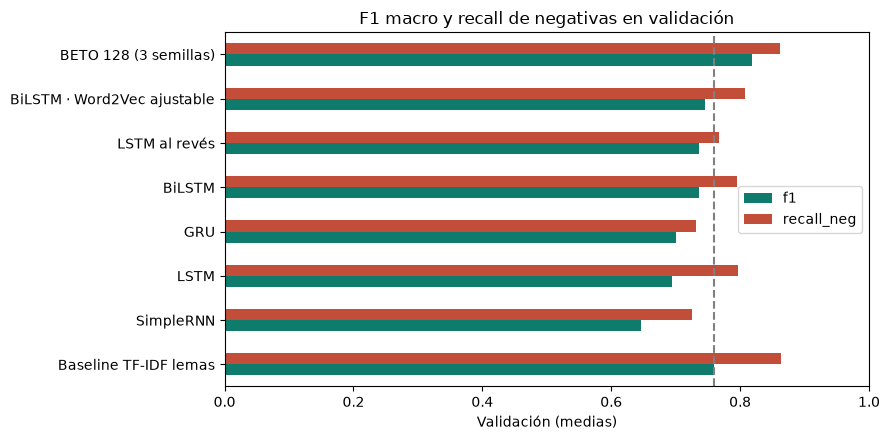

In [37]:
comp_val = pd.DataFrame({
    'Baseline TF-IDF lemas': {'f1': BASE_VAL['f1_macro'], 'recall_neg': BASE_VAL['recall_negativa'], 'f1_neutra': BASE_VAL['f1_neutra']},
    **{n: {'f1': g.f1_macro_val.mean(), 'recall_neg': g.recall_negativa_val.mean(), 'f1_neutra': g.f1_neutra_val.mean()}
       for n, g in semillas.groupby('modelo', sort=False)},
    'BiLSTM · Word2Vec ajustable': {k: emb_rnn[emb_rnn.embedding == 'Word2Vec 100d ajustable'][c].mean()
                                    for k, c in [('f1', 'f1_macro_val'), ('recall_neg', 'recall_negativa_val'), ('f1_neutra', 'f1_neutra_val')]},
    f'BETO {L_BETO} (3 semillas)': {'f1': beto_sem.f1_macro_val.mean(), 'recall_neg': beto_sem.recall_negativa_val.mean(), 'f1_neutra': beto_sem.f1_neutra_val.mean()},
}).T
display(comp_val.round(3))
ax = comp_val[['f1', 'recall_neg']].plot.barh(figsize=(9, 4.5), color=['#0F7B6C', '#C24E3A'])
ax.axvline(BASE_VAL['f1_macro'], ls='--', c='gray'); ax.set_xlim(0, 1); ax.set_xlabel('Validación (medias)')
ax.set_title('F1 macro y recall de negativas en validación'); plt.tight_layout(); plt.show()

**Qué encontramos:** con 3 semillas, **BETO 128 tiene F1 macro de validación 0,819** (rango 0,815 – 0,820, desviación 0,003): es estable. Supera al baseline en +0,059 y a la mejor red recurrente en +0,074. Es el primer modelo del proyecto que mejora claramente la **clase neutra** (F1 0,630 frente a 0,514), que era la más difícil para todos. El recall de negativas es igual al del baseline (0,862 frente a 0,863).

## 9. Selección final con validación y única evaluación en test
Primero se elige el modelo **solo con validación** (regla prerregistrada). Después se abre el test, una sola vez, para todos los candidatos y todos los experimentos. Nada de lo que se vea en test cambia la elección.

Los candidatos son el baseline, la mejor red recurrente (BiLSTM, sección 7.1) y BETO con la longitud elegida en 8.3. Para BiLSTM y BETO se usa como artefacto la corrida con semilla 42; la variación entre semillas se reporta aparte.

In [38]:
candidatos = pd.DataFrame({
    'Baseline': {'f1_macro_val': BASE_VAL['f1_macro'], 'recall_negativa_val': BASE_VAL['recall_negativa'], 'evidencia': 'determinista'},
    'BiLSTM': {'f1_macro_val': semillas[semillas.modelo == 'BiLSTM'].f1_macro_val.mean(),
               'recall_negativa_val': semillas[semillas.modelo == 'BiLSTM'].recall_negativa_val.mean(), 'evidencia': 'media de 5 semillas'},
    'BETO': {'f1_macro_val': beto_sem.f1_macro_val.mean(), 'recall_negativa_val': beto_sem.recall_negativa_val.mean(),
             'evidencia': f'media de 3 semillas, max_length {L_BETO}'}}).T
candidatos[['f1_macro_val', 'recall_negativa_val']] = candidatos[['f1_macro_val', 'recall_negativa_val']].astype(float)
candidatos['ΔF1 vs baseline'] = candidatos.f1_macro_val - BASE_VAL['f1_macro']
candidatos['Δ recall neg vs baseline'] = candidatos.recall_negativa_val - BASE_VAL['recall_negativa']
display(candidatos.round(3))
GANADOR = candidatos.f1_macro_val.idxmax()
H4 = bool(candidatos.loc['BETO', 'ΔF1 vs baseline'] >= .02 and candidatos.loc['BETO', 'Δ recall neg vs baseline'] >= -.01)
print('Modelo elegido con validación (mayor F1 macro):', GANADOR)
print('H4 en validación (BETO ≥ +0,02 de F1 macro sin perder > 0,01 de recall de negativas):', 'se cumple' if H4 else 'no se cumple')

,f1_macro_val,recall_negativa_val,evidencia,ΔF1 vs baseline,Δ recall neg vs baseline
Baseline,0.760,0.863,determinista,0.000,0.000
BiLSTM,0.737,0.795,media de 5 semillas,-0.023,-0.068
BETO,0.819,0.862,"media de 3 semillas, max_length 128",0.059,-0.001


Modelo elegido con validación (mayor F1 macro): BETO
H4 en validación (BETO ≥ +0,02 de F1 macro sin perder > 0,01 de recall de negativas): se cumple


**Qué encontramos:** con la regla prerregistrada **se elige BETO**: +0,059 de F1 macro sobre el baseline en validación, con recall de negativas prácticamente igual (−0,001). **H4 se cumple en validación.** La BiLSTM queda por debajo del baseline (−0,023), como en la sesión 3. Esta decisión se toma antes de abrir el test.

#### 9.1 Única mirada al test: tablero de calidad

In [39]:
pb = modelos_tfidf[champ_tfidf]; col = configs[champ_tfidf][0]
def prep_baseline(textos):
    """Texto normalizado → entrada del baseline (lematiza si el campeón usa lemas)."""
    if col == 'lemas':
        return [' '.join(t.lemma_.lower() for t in d if not t.is_space) for d in nlp.pipe(textos)]
    return list(textos)
lv42, lt42, meta42 = BETO[(L_BETO, SEED)]
P_VA = {'Baseline': pb.predict_proba(va[col]), 'BiLSTM': artefactos['bilstm']['prob_va'], 'BETO': softmax(lv42)}
P_TE = {'Baseline': probs_te[champ_tfidf], 'BiLSTM': artefactos['bilstm']['prob_te'], 'BETO': softmax(lt42)}

UMBRALES = np.round(np.arange(.40, .991, .01), 2)
def elegir_umbral(y_true_txt, prob, meta=.90):
    pred = np.asarray(CLASES)[prob.argmax(1)]; conf = prob.max(1)
    for th in UMBRALES:
        ok = conf >= th
        if ok.any() and (pred[ok] == np.asarray(y_true_txt)[ok]).mean() >= meta: return th
    return UMBRALES[-1]
def cobertura(y_true_txt, prob, th):
    pred = np.asarray(CLASES)[prob.argmax(1)]; ok = prob.max(1) >= th
    return ok.mean(), (pred[ok] == np.asarray(y_true_txt)[ok]).mean()

filas = []
for n in P_TE:
    th = elegir_umbral(va.etiqueta, P_VA[n]); cob, cal = cobertura(te.etiqueta, P_TE[n], th)
    filas.append({'modelo': n, 'f1_macro_val': metricas(va.etiqueta, P_VA[n])['f1_macro'], **metricas(te.etiqueta, P_TE[n]),
                  'umbral_val': th, 'cobertura_test': cob, 'calidad_cubierta_test': cal})
tablero = pd.DataFrame(filas).set_index('modelo')
display(tablero.round(3))

,f1_macro_val,f1_macro,recall_negativa,f1_neutra,log_loss,umbral_val,cobertura_test,calidad_cubierta_test
modelo,,,,,,,,
Baseline,0.760,0.755,0.850,0.520,0.369,0.56,0.887,0.901
BiLSTM,0.743,0.723,0.837,0.473,0.416,0.66,0.842,0.892
BETO,0.820,0.780,0.833,0.560,0.415,0.51,0.997,0.878


In [40]:
# Confirmación de todos los experimentos (validación decide, test confirma)
def medias(d, por, exp):
    g = d.groupby(por, sort=False)
    return pd.DataFrame({'experimento': exp, 'f1_val': g.f1_macro_val.mean(), 'f1_test': g.f1_macro_test.mean(),
                         'recall_neg_val': g.recall_negativa_val.mean(), 'recall_neg_test': g.recall_negativa_test.mean()})
beto_ab = pd.DataFrame([{'cfg': f'BETO {L} · semilla {s}', **{k + '_val': v for k, v in metricas(va.etiqueta, softmax(lv)).items()},
                         **{k + '_test': v for k, v in metricas(te.etiqueta, softmax(lt)).items()}} for (L, s), (lv, lt, _) in BETO.items() if s == SEED])
confirmacion = pd.concat([
    medias(semillas, 'modelo', '7.1 · 5 semillas'),
    medias(largo.assign(cfg=largo.modelo + ' · SEQ_LEN ' + largo.SEQ_LEN.astype(str)), 'cfg', '7.2 · 3 semillas'),
    medias(emb_rnn, 'embedding', '7.3 · BiLSTM, 3 semillas'),
    medias(beto_ab, 'cfg', '8.3 · BETO, semilla 42'),
    medias(beto_sem.assign(cfg=f'BETO {L_BETO} · media'), 'cfg', '8.4 · BETO, 3 semillas'),
    pd.DataFrame({'experimento': 'determinista', 'f1_val': BASE_VAL['f1_macro'], 'f1_test': BASE['f1_macro'],
                  'recall_neg_val': BASE_VAL['recall_negativa'], 'recall_neg_test': BASE['recall_negativa']}, index=['Baseline TF-IDF lemas'])])
display(confirmacion.round(3))
corr_rnn = pd.concat([semillas, largo, emb_rnn[emb_rnn.embedding != EMB_CONFIG[0][0]]])
print('Corridas recurrentes que superan al baseline en test:', int((corr_rnn.f1_macro_test > BASE['f1_macro']).sum()), 'de', len(corr_rnn))
print('Corridas BETO que superan al baseline en test:', int((beto_sem.f1_macro_test > BASE['f1_macro']).sum()), 'de', len(beto_sem))
print(f'¿Validación ordena igual que test? Spearman: {spearmanr(confirmacion.f1_val, confirmacion.f1_test)[0]:.2f}')
d_f1 = beto_sem.f1_macro_test.mean() - BASE['f1_macro']; d_rec = beto_sem.recall_negativa_test.mean() - BASE['recall_negativa']
print(f'H4 en test (media de 3 semillas de BETO): ΔF1 {d_f1:+.3f}, Δ recall de negativas {d_rec:+.3f} → '
      f"{'se confirma' if d_f1 >= .02 and d_rec >= -.01 else 'no se confirma'}")

,experimento,f1_val,f1_test,recall_neg_val,recall_neg_test
SimpleRNN,7.1 · 5 semillas,0.646,0.629,0.726,0.679
LSTM,7.1 · 5 semillas,0.694,0.692,0.797,0.780
GRU,7.1 · 5 semillas,0.700,0.699,0.732,0.719
BiLSTM,7.1 · 5 semillas,0.737,0.725,0.795,0.778
LSTM al revés,7.1 · 5 semillas,0.737,0.724,0.766,0.758
LSTM · SEQ_LEN 153,7.2 · 3 semillas,0.707,0.710,0.768,0.752
LSTM · SEQ_LEN 252,7.2 · 3 semillas,0.698,0.695,0.827,0.807
BiLSTM · SEQ_LEN 153,7.2 · 3 semillas,0.737,0.725,0.765,0.755
BiLSTM · SEQ_LEN 252,7.2 · 3 semillas,0.726,0.713,0.833,0.806
Aleatorio 64d · 20.000 (7.1),"7.3 · BiLSTM, 3 semillas",0.737,0.725,0.765,0.755


Corridas recurrentes que superan al baseline en test: 0 de 46
Corridas BETO que superan al baseline en test: 3 de 3
¿Validación ordena igual que test? Spearman: 0.92
H4 en test (media de 3 semillas de BETO): ΔF1 +0.029, Δ recall de negativas -0.003 → se confirma


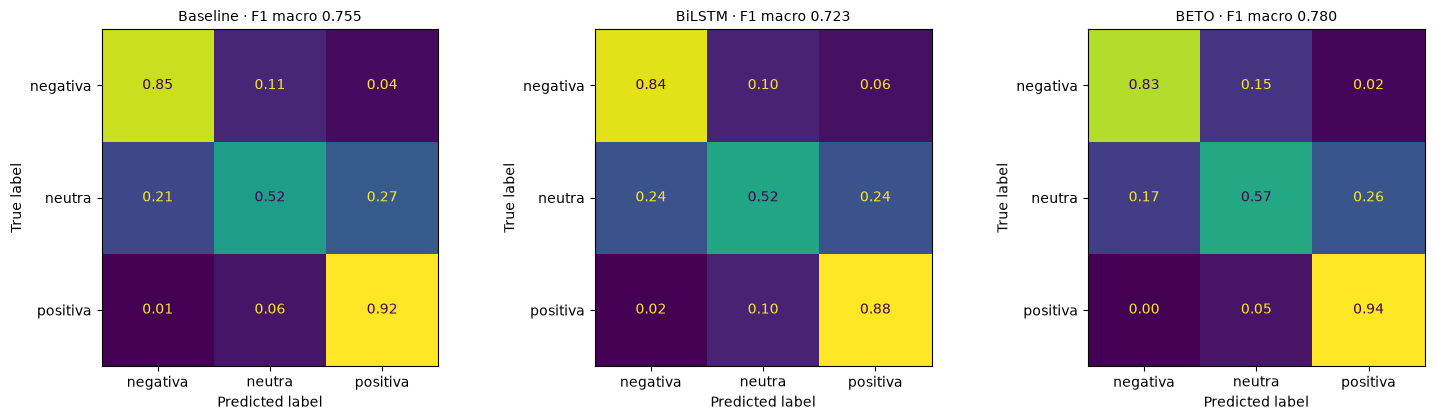

— Baseline (test) —
              precision    recall  f1-score   support
    negativa      0.780     0.850     0.813       412
      neutra      0.522     0.519     0.520       349
    positiva      0.941     0.924     0.932      1910
    accuracy                          0.859      2671
   macro avg      0.747     0.764     0.755      2671
weighted avg      0.861     0.859     0.860      2671
— BETO (test) —
              precision    recall  f1-score   support
    negativa      0.835     0.833     0.834       412
      neutra      0.550     0.570     0.560       349
    positiva      0.948     0.942     0.945      1910
    accuracy                          0.877      2671
   macro avg      0.778     0.782     0.780      2671
weighted avg      0.879     0.877     0.878      2671


In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, n in zip(axes, P_TE):
    ConfusionMatrixDisplay.from_predictions(te.etiqueta, np.asarray(CLASES)[P_TE[n].argmax(1)], labels=CLASES,
                                            normalize='true', values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(f"{n} · F1 macro {tablero.loc[n, 'f1_macro']:.3f}", fontsize=10)
plt.tight_layout(); plt.show()
for n in ['Baseline', GANADOR] if GANADOR != 'Baseline' else ['Baseline', 'BETO']:
    print(f'— {n} (test) —'); print(classification_report(te.etiqueta, np.asarray(CLASES)[P_TE[n].argmax(1)], digits=3))

**Qué encontramos (única mirada al test):**

| | Baseline TF-IDF | BiLSTM | **BETO** |
|---|---|---|---|
| F1 macro test | 0,755 | 0,723 | **0,780** (media de 3 semillas: 0,784) |
| Recall negativas | **0,850** | 0,837 | 0,833 (media: 0,846) |
| Precisión negativas | 0,780 | 0,744 | **0,835** |
| F1 neutra | 0,520 | 0,473 | **0,560** |
| Log loss | **0,369** | 0,416 | 0,415 |

- **El test confirma la elección:** BETO es el mejor en F1 macro y **las 3 semillas superan al baseline en test**, mientras que **ninguna de las 46 corridas recurrentes** lo logra. **H4 se confirma en test:** +0,029 de F1 macro y −0,003 de recall de negativas (media de 3 semillas).
- **Validación fue optimista con BETO:** 0,820 en validación frente a 0,780 en test (−0,04), contra −0,005 del baseline. La época se eligió con validación, y eso infla esa cifra. Aun así, validación ordena los modelos igual que test (Spearman 0,92).
- **La mejora está en la frontera neutra:** BETO detecta casi lo mismo que el baseline en negativas (0,833 frente a 0,850 con la semilla 42), pero con **menos falsas alarmas** (precisión 0,835 frente a 0,780) y mejor F1 neutra.
- **Log loss alto pese a mejor F1:** BETO está **sobreconfiado** (ver 9.3).

#### 9.2 Calidad frente a cobertura (abstención)

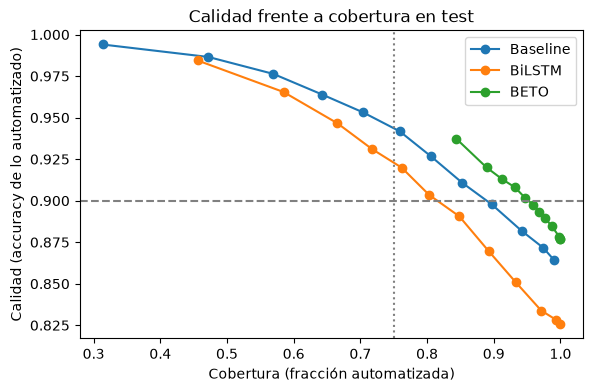

,umbral_val,cobertura_test,calidad_cubierta_test,a revisión por cada 1.000
modelo,,,,
Baseline,0.56,0.887,0.901,113.0
BiLSTM,0.66,0.842,0.892,158.0
BETO,0.51,0.997,0.878,3.0


In [42]:
def quality_coverage(y_true_txt, prob):
    pred = np.asarray(CLASES)[prob.argmax(1)]; conf = prob.max(1); y = np.asarray(y_true_txt)
    return pd.DataFrame([[th, (conf >= th).mean(), (pred[conf >= th] == y[conf >= th]).mean()] for th in UMBRALES[::5]],
                        columns=['umbral', 'cobertura', 'calidad'])
fig, ax = plt.subplots(figsize=(6.5, 4))
for n in P_TE:
    q = quality_coverage(te.etiqueta, P_TE[n]); ax.plot(q.cobertura, q.calidad, marker='o', label=n)
ax.axhline(.9, ls='--', c='gray'); ax.axvline(.75, ls=':', c='gray')
ax.set_xlabel('Cobertura (fracción automatizada)'); ax.set_ylabel('Calidad (accuracy de lo automatizado)')
ax.legend(); ax.set_title('Calidad frente a cobertura en test'); plt.show()
display(tablero[['umbral_val', 'cobertura_test', 'calidad_cubierta_test']].assign(
    **{'a revisión por cada 1.000': lambda d: ((1 - d.cobertura_test) * 1000).round(0)}).round(3))

**Qué encontramos:** el baseline automatiza el **88,7 %** con calidad **0,901** y manda a revisión 113 de cada 1.000 reseñas. **BETO, con el umbral elegido en validación (0,51), automatiza el 99,7 % pero con calidad 0,878**: en validación su acierto era tan alto que casi cualquier umbral cumplía 0,90, y en test no se sostiene. Es la consecuencia práctica de que validación fuera optimista con BETO. **El umbral de BETO debe recalibrarse con datos auditados en el piloto**, no copiarse de validación.

#### 9.3 Calibración y *temperature scaling*
Se mide el ECE (error de calibración esperado) de los tres modelos. A BETO se le ajusta una **temperatura** con los logits de **validación** (minimiza el log loss); no cambia la clase predicha, solo qué tan seguras son las probabilidades.

Temperatura elegida en validación: 1.68


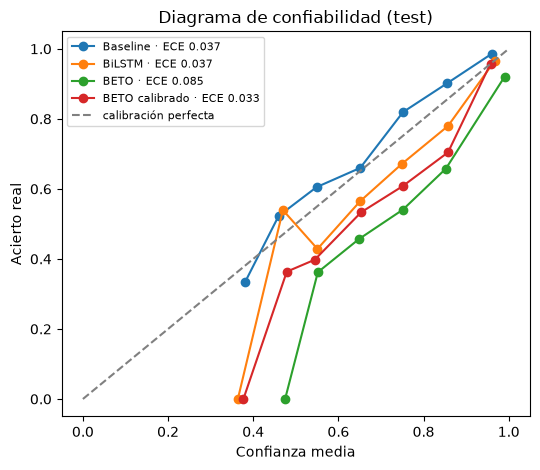

,ECE test,log loss test
Baseline,0.037,0.369
BiLSTM,0.037,0.416
BETO,0.085,0.415
BETO calibrado,0.033,0.324


In [43]:
def ece(y_true_txt, prob, bins=10):
    y = np.asarray(y_true_txt); acc = np.asarray(CLASES)[prob.argmax(1)] == y; conf = prob.max(1); e, filas = 0, []
    for a, b in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > a) & (conf <= b)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean()); filas.append((conf[m].mean(), acc[m].mean()))
    return e, np.array(filas)
T_BETO = minimize_scalar(lambda T: log_loss(va.etiqueta, softmax(lv42 / T), labels=CLASES), bounds=(.5, 5), method='bounded').x
P_VA['BETO calibrado'] = softmax(lv42 / T_BETO); P_TE['BETO calibrado'] = softmax(lt42 / T_BETO)
print(f'Temperatura elegida en validación: {T_BETO:.2f}')
fig, ax = plt.subplots(figsize=(5.5, 4.8)); cal_tab = {}
for n in P_TE:
    e, f = ece(te.etiqueta, P_TE[n]); cal_tab[n] = {'ECE test': e, 'log loss test': log_loss(te.etiqueta, P_TE[n], labels=CLASES)}
    ax.plot(f[:, 0], f[:, 1], marker='o', label=f'{n} · ECE {e:.3f}')
ax.plot([0, 1], [0, 1], '--', c='gray', label='calibración perfecta'); ax.set_xlabel('Confianza media'); ax.set_ylabel('Acierto real')
ax.set_title('Diagrama de confiabilidad (test)'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame(cal_tab).T.round(3))

#### 9.4 Política para la clase crítica: regla P(negativa) ≥ t
En vez de `argmax`, se marca "negativa" cuando su probabilidad supera un umbral `t`, elegido en **validación** como el mayor que deja recall de negativas ≥ 0,90. Luego se mide en test.

In [44]:
i_neg = CLASES.index('negativa')
def aplicar_regla(p, t): return np.where(p[:, i_neg] >= t, 'negativa', np.asarray(CLASES)[p.argmax(1)])
def elegir_t(p_va, meta=.90):
    return next((t for t in np.round(np.arange(.50, .01, -.01), 2)
                 if recall_score(va.etiqueta, aplicar_regla(p_va, t), labels=['negativa'], average='macro') >= meta), .01)
def resumen_politica(pred):
    yt = te.etiqueta.values
    return {'recall_negativa': recall_score(yt, pred, labels=['negativa'], average='macro'),
            'precision_negativa': precision_score(yt, pred, labels=['negativa'], average='macro'),
            'f1_macro': f1_score(yt, pred, average='macro'), '% marcadas negativas': (pred == 'negativa').mean() * 100}
T_NEG, regla = {}, {}
for n in ['Baseline', 'BiLSTM', 'BETO calibrado']:
    T_NEG[n] = elegir_t(P_VA[n])
    regla[f'{n} · argmax'] = {'t': 'argmax', **resumen_politica(np.asarray(CLASES)[P_TE[n].argmax(1)])}
    regla[f'{n} · regla'] = {'t': T_NEG[n], **resumen_politica(aplicar_regla(P_TE[n], T_NEG[n]))}
regla = pd.DataFrame(regla).T
for c in ['recall_negativa', 'precision_negativa', 'f1_macro', '% marcadas negativas']: regla[c] = regla[c].astype(float)
display(regla.round(3))

,t,recall_negativa,precision_negativa,f1_macro,% marcadas negativas
Baseline · argmax,argmax,0.850,0.780,0.755,16.810
Baseline · regla,0.35,0.891,0.728,0.741,18.869
BiLSTM · argmax,argmax,0.837,0.744,0.723,17.372
BiLSTM · regla,0.29,0.874,0.716,0.718,18.832
BETO calibrado · argmax,argmax,0.833,0.835,0.780,15.387
BETO calibrado · regla,0.19,0.888,0.806,0.780,16.997


**Qué encontramos:**
- **Calibración:** BETO está **sobreconfiado** (ECE 0,085, frente a 0,037 del baseline y de la BiLSTM). Con *temperature scaling* (T = 1,68, ajustada en validación) baja a **0,033** y su log loss pasa de 0,415 a **0,324**, el mejor de todos los modelos. La temperatura no cambia la clase predicha, solo la confianza.
- **Regla para la clase crítica:** marcar "negativa" si P(negativa) ≥ t (t elegido en validación) sube el recall de negativas a **0,891** en el baseline (t = 0,35), **0,888** en BETO calibrado (t = 0,19) y 0,874 en la BiLSTM. **Ninguno llega a 0,90 en test.**
- **BETO lo logra con menos ruido:** marca el 17,0 % de las reseñas como negativas (precisión 0,806), frente al 18,9 % del baseline (precisión 0,728). Para el coordinador de sede son unas 370 falsas alarmas menos por cada 20.000 reseñas.

## 10. Análisis de errores del modelo elegido
Se etiquetan **automáticamente** las posibles causas de cada error y se mide su *lift* (frecuencia en errores ÷ frecuencia en aciertos). Después se leen a mano 24 errores (4 por cada par verdad → predicción, los de mayor confianza) y se asigna a cada uno su causa principal.

In [45]:
NOMBRE_G = 'BETO' if GANADOR == 'BETO' else GANADOR
prob_g = P_TE[NOMBRE_G]
n_sub_te = n_sub(te.texto)
ana = te[['texto', 'etiqueta', 'cortado_fuente', 'sin_hotel']].copy()
ana['pred'] = np.asarray(CLASES)[prob_g.argmax(1)]; ana['conf'] = prob_g.max(1)
for n in ['Baseline', 'BiLSTM', 'BETO']:
    if n != NOMBRE_G: ana[f'pred_{n}'] = np.asarray(CLASES)[P_TE[n].argmax(1)]
ana['n_palabras'] = ana.texto.map(lambda s: len(tokenizar(s)))
ana['oov'] = [(x == 1).sum() / max((x != 0).sum(), 1) for x in Xte_s]
truncada = {'BETO': n_sub_te > L_BETO, 'BiLSTM': ana.n_palabras.values > SEQ_LEN, 'Baseline': np.zeros(len(te), bool)}[NOMBRE_G]
low = ana.texto.str.lower()
causas = pd.DataFrame({
    'neutra involucrada': (ana.etiqueta == 'neutra') | (ana.pred == 'neutra'),
    'negación': low.str.contains(r'\b(?:no|nunca|ni|tampoco|nada)\b'),
    'contraste': low.str.contains(r'\b(?:pero|aunque|sin embargo|no obstante|eso sí)\b'),
    'truncada por el modelo': truncada,
    'cortada en la fuente': ana.cortado_fuente,
    'palabras raras (OOV > 5 %)': ana.oov > .05,
    'sin hotel (otra fuente)': ana.sin_hotel,
}, index=ana.index)
err = ana.pred != ana.etiqueta
lift = pd.DataFrame({'% en errores': causas[err].mean() * 100, '% en aciertos': causas[~err].mean() * 100})
lift['lift'] = lift['% en errores'] / lift['% en aciertos']
print(f'Modelo analizado: {NOMBRE_G} · errores: {err.sum()} de {len(ana)} ({err.mean():.1%})')
display(lift.round(2).sort_values('lift', ascending=False))
display(pd.crosstab(ana.etiqueta[err], ana.pred[err], rownames=['verdad'], colnames=['predicción']))
otros = [c for c in ana if c.startswith('pred_')]
print('Errores que también comete cada otro modelo:', {c: f'{(ana.loc[err, c] != ana.loc[err, "etiqueta"]).mean():.0%}' for c in otros})

Modelo analizado: BETO · errores: 329 de 2671 (12.3%)


,% en errores,% en aciertos,lift
neutra involucrada,95.14,8.50,11.20
cortada en la fuente,16.41,9.31,1.76
contraste,63.53,38.22,1.66
negación,72.04,49.49,1.46
truncada por el modelo,39.21,27.24,1.44
palabras raras (OOV > 5 %),22.19,19.09,1.16
sin hotel (otra fuente),15.50,14.47,1.07


predicción,negativa,neutra,positiva
verdad,,,
negativa,0,60,9
neutra,61,0,89
positiva,7,103,0


Errores que también comete cada otro modelo: {'pred_Baseline': '68%', 'pred_BiLSTM': '70%'}


**Qué encontramos (BETO, 329 errores = 12,3 %, frente a 14,1 % del baseline):**
- **El 95 % de los errores involucra a la clase neutra** (lift 11,2). Las confusiones principales son positiva → neutra (103) y neutra → positiva (89). Confundir negativa con positiva es raro (9 + 7).
- Las causas textuales más asociadas al error son **cortada en la fuente** (lift 1,76), **contraste** ("pero", "aunque", lift 1,66), **negación** (1,46) y **truncada por el modelo** (1,44): las reseñas con matices, y las que pierden el final, son las difíciles.
- Las palabras raras y la fuente casi no influyen (lift 1,07 a 1,16).
- **El 68 % de los errores de BETO también los comete el baseline** y el 70 % la BiLSTM: son, en su mayoría, casos difíciles por los datos, no por la arquitectura.

In [46]:
ana['causas'] = causas.apply(lambda r: ', '.join(c for c in causas.columns if r[c]), axis=1)
muestra_err = ana[err].sort_values('conf', ascending=False).groupby(['etiqueta', 'pred'], group_keys=False).head(4).reset_index(drop=True)
pd.set_option('display.max_colwidth', 260)
display(muestra_err.assign(texto=muestra_err.texto.str[:260])[['etiqueta', 'pred', 'conf'] + otros + ['causas', 'texto']].round(2))
pd.set_option('display.max_colwidth', 120)

,etiqueta,pred,conf,pred_Baseline,pred_BiLSTM,causas,texto
0,neutra,positiva,1.00,positiva,positiva,"neutra involucrada, negación, contraste","Muy buena ubicación . El hotel está situado en un sitio privilegiado, estás cerca de todo y no hace falta mover el coche se puede llegar andando a todas partes. El trato del personal del hotel estupendo, los chicos de recepción inmejorables todos nos han a..."
1,neutra,positiva,1.00,positiva,positiva,"neutra involucrada, negación","Muy correcto. Céntrico, cómodo, limpio, tranquilo y con un buen desayuno. Lo reservamos para una noche, nos atrajo su precio, servicios y comentarios y no nos ha defraudado. Si volvemos a Córdoba en plan tranquilo y trotero, sin duda lo reservaba de nuevo."
2,neutra,positiva,1.00,positiva,positiva,"neutra involucrada, palabras raras (OOV > 5 %)","Muy bonito. Tipico patio Cordobes con sus plantas y fuentes con el suelo enpedrado, tomamos unos cafes y disfrutamos de este ambiente Cordobes. Lo curioso es que el patio tiene aire acodicionado y un techo de sombreo."
3,neutra,negativa,1.00,negativa,negativa,"neutra involucrada, negación, contraste, truncada por el modelo, palabras raras (OOV > 5 %)","Me han querido cobrar con 300 días de antelación. Me he hospedado muchas veces en este lugar y viajo constantemente por España hospedándome en muchos otros, pero lo que acaba de pasar es alucinante! Hice una reserva no reembolsable para las Navidades, o se..."
4,neutra,positiva,1.00,positiva,positiva,"neutra involucrada, negación","Estancia.. Nos quedamos dos días en el hotel apartamento, nos llevamos a nuestra perrita ya que el hotel aceptan mascotas algo que nos encantó, al llegar tienen un bebedero para que puedan beber un detalle. Las habitaciones son muy amplias, lo único es que..."
5,neutra,negativa,1.00,negativa,negativa,"neutra involucrada, negación, contraste, truncada por el modelo, palabras raras (OOV > 5 %), sin hotel (otra fuente)","decepcionante!!. Estuve alojada este fin de semana pasado con mi pareja y no me gustò nada la comida del hotel, solo estuvimos dos dias en regimen mp, pero menuda sorpresa cuando llegamos alli y vemos k no hay nada de variedad, la comida insipida, sin sabo..."
6,neutra,negativa,1.00,negativa,negativa,"neutra involucrada, negación, contraste, truncada por el modelo","MALA EXPERIENCIA SIN RECEPCION. Reservamos dos apartamentos para dos familias que íbamos a una boda, al principio todo correcto porque aunque no tienen recepción, nos atendieron a la hora que les dijimos que llegaríamos, nos entregaron las llaves (un juego..."
7,neutra,negativa,1.00,negativa,negativa,"neutra involucrada, negación, contraste, truncada por el modelo, palabras raras (OOV > 5 %), sin hotel (otra fuente)","desastre, se oye todo y no se puede dormir. El hotel es bonito, muy bien decorado, pero claro a mi novio y a mi nos toco dormir en dos camas juntas, vamos una doble ,se dormia fatal. Por la noche es imposible dormir alli por el ruido, el de al lao vino de ..."
8,negativa,positiva,1.00,positiva,positiva,negación,"Presentación de exámenes. Mi estancia fue agradable y cómoda, el personal muy simpático y amable, el desayuno de lo más variado(fruta,embutido,pastelitos,zumos varios...), se agradece no siempre encontrar 2 o 3 cositas sólo, si vuelvo a Sevilla volveré."
9,negativa,positiva,0.99,positiva,positiva,palabras raras (OOV > 5 %),"Avoid this place. Arroyo Frio is located in the heart of the biggest Spain's natural protected zone. You could expect a place like a quiet mountain resort, you are completely wrong. You will find a crowded, noisy and chaotic cheap beach camp, a pity. Avoid..."


**Lectura manual de los 24 errores** (# = fila de la tabla anterior). Cada error se asigna a su causa principal después de leer el texto:

| Causa principal | Errores | Cuántos | Ejemplo |
|---|---|---|---|
| **Etiqueta ruidosa**: las estrellas no coinciden con el texto | 0, 1, 2, 3, 5, 6, 7, 8, 18, 19 | **10** | #6 "MALA EXPERIENCIA SIN RECEPCION" tiene 3 ★; #8 y #19 son elogios con 1-2 ★; #18 "POR MEJORAR" (deterioro, grifos que gotean) tiene 4-5 ★. |
| **Reseña mixta** ("lo bueno / lo malo"): frontera neutra subjetiva | 4, 10, 11, 12, 13, 14, 15, 16, 17, 23 | **10** | #15 "Bien en general con algunos matices" tiene 4-5 ★ y BETO dice neutra; #13 "Normal normal. Ni bueno ni cutre" tiene 1-2 ★. |
| **Otro idioma** | 9, 20, 21 | 3 | #9 y #20 en inglés ("Avoid this place", "Unhelpful, unfriendly & noisy") salen positivas con 0,99 de confianza. |
| **Elogio cortado al final** | 22 | 1 | #22 empieza con la queja del aire acondicionado y el texto se corta en "El servicio exce…". |

**Conclusiones del análisis:**
1. **En 21 de los 24 errores el baseline también se equivoca**; solo acierta #12, #14 y #22. La BiLSTM acierta 4 (#10, #11, #12 y #14).
2. **10 de 24 son ruido de etiqueta:** la etiqueta viene de las estrellas y no siempre coincide con el texto. Esto pone un techo a cualquier modelo. En Bodytech, la etiqueta debería venir de la calificación **más** una revisión del texto en una muestra.
3. **Los 24 errores tienen confianza ≥ 0,89 sin calibrar.** Ningún umbral de abstención los detiene: hacen falta la calibración (9.3), el detector de idioma y la auditoría aleatoria.

## 11. Robustez, fuera de dominio, otros idiomas y segmentos
Los tres modelos se prueban con las mismas entradas. BETO se usa desde el modelo guardado en disco (el mismo que usará la demo).

In [47]:
beto_final = AutoModelForSequenceClassification.from_pretrained(MODELOS + f'beto/beto_L{L_BETO}_s{SEED}/modelo').to(DISPOSITIVO).eval()
@torch.inference_mode()
def beto_logits(textos, bs=64, modelo=None, disp=None):
    modelo, disp = modelo or beto_final, disp or DISPOSITIVO; out = []
    for i in range(0, len(textos), bs):
        b = tok_beto(list(textos[i:i + bs]), truncation=True, max_length=L_BETO, padding=True, return_tensors='pt').to(disp)
        out.append(modelo(**b).logits.float().cpu().numpy())
    return np.concatenate(out)
def predecir(nombre, textos):
    textos = [normalizar(t) for t in textos]
    if nombre == 'Baseline': return pb.predict_proba(prep_baseline(textos))
    if nombre == 'BiLSTM': return artefactos['bilstm']['modelo'].predict(tv(tf.constant(textos)), verbose=0)
    return softmax(beto_logits(textos))
chk = np.abs(predecir('BETO', te.texto.tolist()[:256]) - P_TE['BETO'][:256]).max()
print(f'Control: modelo cargado de disco frente a la corrida original, diferencia máxima de probabilidad {chk:.4f}')

robustez = pd.DataFrame({'caso': ['afirmación', 'negación', 'contraste', 'errores ortográficos', 'mayúsculas + !!!',
                                  'emoji', 'neutra', 'ironía', 'fuera de dominio', 'otro idioma', 'vacío', 'repetición larga'],
    'texto': ['La habitación estaba limpia y el personal fue muy amable.',
              'La habitación no estaba limpia y el personal no fue amable.',
              'La ubicación es buena, pero la habitación estaba sucia y había mucho ruido.',
              'La avitacion estava susia y el personal fue maleducado',
              'HORRIBLE. NUNCA MÁS VOLVEMOS!!!',
              'Todo perfecto 😍😍',
              'Hotel correcto, nada especial. Cumple para una noche.',
              'Genial, solo tardaron dos horas en darnos la habitación. Maravilloso.',
              'La fotosíntesis depende de la luz.',
              'The room was dirty and the staff was rude.',
              '',
              'bien ' * 300]})
for n in ['Baseline', 'BiLSTM', 'BETO']:
    p = predecir(n, robustez.texto.tolist()); robustez[n] = [f'{CLASES[i]} ({q.max():.2f})' for i, q in zip(p.argmax(1), p)]
robustez['texto'] = robustez.texto.str[:60]
display(robustez)

Control: modelo cargado de disco frente a la corrida original, diferencia máxima de probabilidad 0.0000


,caso,texto,Baseline,BiLSTM,BETO
0,afirmación,La habitación estaba limpia y el personal fue muy amable.,positiva (0.86),neutra (0.49),positiva (0.51)
1,negación,La habitación no estaba limpia y el personal no fue amable.,neutra (0.86),neutra (0.52),negativa (0.96)
2,contraste,"La ubicación es buena, pero la habitación estaba sucia y hab",neutra (0.85),neutra (0.58),negativa (0.88)
3,errores ortográficos,La avitacion estava susia y el personal fue maleducado,positiva (0.63),negativa (0.60),negativa (0.94)
4,mayúsculas + !!!,HORRIBLE. NUNCA MÁS VOLVEMOS!!!,negativa (0.91),positiva (0.52),negativa (0.95)
5,emoji,Todo perfecto 😍😍,positiva (0.99),positiva (0.81),positiva (1.00)
6,neutra,"Hotel correcto, nada especial. Cumple para una noche.",neutra (0.91),neutra (0.83),neutra (0.98)
7,ironía,"Genial, solo tardaron dos horas en darnos la habitación. Mar",positiva (0.56),positiva (0.73),positiva (0.99)
8,fuera de dominio,La fotosíntesis depende de la luz.,negativa (0.56),negativa (0.59),neutra (0.48)
9,otro idioma,The room was dirty and the staff was rude.,positiva (0.65),neutra (0.45),positiva (0.77)


**Qué encontramos (contrafactuales):**
- **Negación y contraste:** "La habitación **no** estaba limpia…" y "La ubicación es buena, **pero** la habitación estaba sucia…" → **BETO dice negativa** (0,96 y 0,88); el baseline y la BiLSTM dicen neutra. Es la ventaja de leer el contexto completo.
- **Errores ortográficos y mayúsculas cortas:** BETO acierta "avitacion estava susia…" (0,94) y "HORRIBLE. NUNCA MÁS VOLVEMOS!!!" (0,95).
- **Ironía:** "Genial, solo tardaron dos horas…" → positiva en los tres modelos; BETO con **0,99** de confianza. Ninguno entiende el sarcasmo.
- **Otro idioma:** "The room was dirty and the staff was rude." → **positiva** en BETO (0,77) y en el baseline. Hace falta el detector de idioma.
- **Fuera de dominio y vacío:** BETO da baja confianza ("La fotosíntesis…" → neutra 0,48; vacío → 0,36), así que ambos irían a revisión humana con el umbral.
- **"bien" × 300:** BETO dice positiva con 0,69; la BiLSTM, neutra con 0,99. Una entrada absurda no debería llegar al modelo: se filtra por longitud y repetición.
- El control confirma que el modelo cargado de disco da **exactamente** las mismas probabilidades que la corrida original (diferencia 0,0000).

#### 11.1 Robustez sobre **todo** el test

In [48]:
rng_t = np.random.default_rng(SEED)
def con_errores(s, p=.15):
    def danar(w):
        if len(w) < 4 or rng_t.random() > p: return w
        i, op = int(rng_t.integers(1, len(w) - 2)), int(rng_t.integers(3))
        if op == 0: return w[:i] + w[i + 1:]
        if op == 1: return w[:i] + w[i + 1] + w[i] + w[i + 2:]
        return w[:i] + str(rng_t.choice(list('aeiourstnl'))) + w[i + 1:]
    return ' '.join(danar(w) for w in s.split(' '))
sin_tildes = lambda s: ''.join(ch for ch in unicodedata.normalize('NFD', s) if unicodedata.category(ch) != 'Mn')
variantes = {'original': te.texto, 'errores de tipeo (15 %)': te.texto.map(con_errores),
             'sin tildes ni eñes': te.texto.map(sin_tildes), 'todo en mayúsculas': te.texto.str.upper()}
filas = []
for nombre, textos in variantes.items():
    for n in ['Baseline', 'BiLSTM', 'BETO']:
        mm = metricas(te.etiqueta, predecir(n, textos.tolist()))
        filas.append({'variante': nombre, 'modelo': n, 'f1_macro': mm['f1_macro'], 'recall_negativa': mm['recall_negativa']})
rob_total = pd.DataFrame(filas).pivot(index='variante', columns='modelo', values=['f1_macro', 'recall_negativa']).loc[list(variantes)]
display(rob_total.round(3))
print('Caída de F1 macro frente al original:'); display((rob_total['f1_macro'] - rob_total['f1_macro'].loc['original']).round(3))

f1_macro                 recall_negativa           \
modelo                      BETO Baseline BiLSTM            BETO Baseline   
variante                                                                    
original                   0.780    0.755  0.723           0.833    0.850   
errores de tipeo (15 %)    0.784    0.738  0.675           0.854    0.852   
sin tildes ni eñes         0.788    0.744  0.719           0.845    0.874   
todo en mayúsculas         0.590    0.755  0.691           0.852    0.833   

                                
modelo                  BiLSTM  
variante                        
original                 0.837  
errores de tipeo (15 %)  0.910  
sin tildes ni eñes       0.845  
todo en mayúsculas       0.881

Caída de F1 macro frente al original:


modelo,BETO,Baseline,BiLSTM
variante,,,
original,0.000,0.000,0.000
errores de tipeo (15 %),0.004,-0.017,-0.048
sin tildes ni eñes,0.009,-0.011,-0.004
todo en mayúsculas,-0.190,-0.000,-0.032


**Qué encontramos (todo el test):**

| Variante | Caída F1 Baseline | Caída F1 BiLSTM | Caída F1 BETO |
|---|---|---|---|
| Errores de tipeo (15 % de palabras) | −0,017 | −0,048 | **+0,004** |
| Sin tildes ni eñes | −0,011 | −0,004 | +0,009 |
| **Todo en mayúsculas** | 0,000 | −0,032 | **−0,190** |

- **BETO es el más robusto a errores de tipeo y tildes:** las subpalabras recomponen las palabras mal escritas.
- **Pero se cae con texto en mayúsculas** (0,780 → 0,590). BETO distingue mayúsculas (*cased*) y casi no vio reseñas enteras en mayúsculas. El caso aislado "HORRIBLE. NUNCA MÁS…" lo acertaba; en todo el test, no: otra vez, un caso aislado no basta para concluir.
- **Control obligatorio para producción:** si una reseña viene mayoritariamente en mayúsculas, pasarla a minúsculas con la primera letra en mayúscula antes de clasificarla. Se propone, pero **no se probó** en este notebook: es parte del piloto.
- El recall de negativas de BETO no baja en ninguna variante (0,833 a 0,854).

#### 11.2 Reseñas en otros idiomas

In [49]:
SW_ES = set('de la que el en y a los se del las un por con no una su para es al lo como más pero sus le ya o fue este ha muy'.split())
def es_espanol(s, minimo=.08):
    t = tokenizar(s); return bool(t) and np.mean([w in SW_ES for w in t]) >= minimo
df_es = df.solo_resena.map(es_espanol); te_es = df_es.loc[te.index].values
print(f'Reseñas que no parecen español: {(~df_es).sum()} en el corpus ({(~df_es).mean():.1%}) · {(~te_es).sum()} en test')
filas = []
for n in ['Baseline', 'BiLSTM', 'BETO']:
    prob = P_TE[n]; pred = np.asarray(CLASES)[prob.argmax(1)]; e = pred != te.etiqueta.values
    filas.append({'modelo': n, '% error en español': e[te_es].mean() * 100, '% error otro idioma': e[~te_es].mean() * 100,
                  'confianza media de esos errores': prob.max(1)[e & ~te_es].mean(),
                  'F1 macro test completo': f1_score(te.etiqueta, pred, average='macro'),
                  'F1 macro solo español': f1_score(te.etiqueta.values[te_es], pred[te_es], average='macro')})
display(pd.DataFrame(filas).set_index('modelo').round(3))

Reseñas que no parecen español: 85 en el corpus (0.6%) · 25 en test


,% error en español,% error otro idioma,confianza media de esos errores,F1 macro test completo,F1 macro solo español
modelo,,,,,
Baseline,13.946,28.0,0.652,0.755,0.758
BiLSTM,17.271,40.0,0.828,0.723,0.726
BETO,12.132,32.0,0.787,0.780,0.783


**Qué encontramos:** hay **85 reseñas que no parecen español** (0,6 %; 25 en test). BETO se equivoca en el **32 %** de ellas (12 % en español) con confianza media **0,79**, así que la abstención no las frena. Quitarlas casi no cambia el F1 macro de BETO (0,780 → 0,783). **Decisión:** no se eliminan del experimento, pero en producción se pone un **detector de idioma antes del modelo**.

#### 11.3 Desempeño por segmento: provincia, fuente, longitud y corte en la fuente
En Bodytech, la provincia equivale a la ciudad y la fuente a un canal distinto. Se reportan los segmentos con al menos 50 reseñas de test.

In [50]:
prov = te.location.fillna('').str.extract(r'^([A-Za-z]+)')[0].fillna('(sin hotel/ubicación)')
prov[te.location.isna().values] = '(sin hotel/ubicación)'
terc = np.percentile(long_tr, [33, 67])
segmentos = {f'provincia · {p}': (prov == p).values for p in prov.value_counts().index}
segmentos.update({'fuente · con hotel': ~te.sin_hotel.values, 'fuente · sin hotel': te.sin_hotel.values,
                  f'longitud · corta (≤ {terc[0]:.0f} palabras)': (ana.n_palabras <= terc[0]).values,
                  'longitud · media': ((ana.n_palabras > terc[0]) & (ana.n_palabras <= terc[1])).values,
                  f'longitud · larga (> {terc[1]:.0f} palabras)': (ana.n_palabras > terc[1]).values,
                  'cortada en la fuente': te.cortado_fuente.values})
filas = []
for nombre, m in segmentos.items():
    if m.sum() < 50: continue
    y = te.etiqueta.values[m]; fila = {'segmento': nombre, 'n': int(m.sum()), 'negativas': int((y == 'negativa').sum())}
    for n in ['Baseline', 'BiLSTM', 'BETO']:
        pr = np.asarray(CLASES)[P_TE[n][m].argmax(1)]
        fila[f'F1 {n}'] = f1_score(y, pr, average='macro')
        fila[f'recall neg {n}'] = recall_score(y, pr, labels=['negativa'], average='macro', zero_division=np.nan)
    filas.append(fila)
segmentos_tab = pd.DataFrame(filas).set_index('segmento'); display(segmentos_tab.round(3))

,n,negativas,F1 Baseline,recall neg Baseline,F1 BiLSTM,recall neg BiLSTM,F1 BETO,recall neg BETO
segmento,,,,,,,,
provincia · Seville,594,86,0.749,0.826,0.713,0.837,0.756,0.814
provincia · Cordoba,453,44,0.748,0.818,0.736,0.886,0.802,0.886
provincia · Granada,441,51,0.744,0.843,0.697,0.804,0.761,0.804
provincia · Malaga,394,53,0.715,0.849,0.690,0.774,0.767,0.736
provincia · (sin hotel/ubicación),390,110,0.779,0.900,0.720,0.873,0.812,0.918
provincia · Almeria,181,29,0.786,0.862,0.797,0.897,0.777,0.793
provincia · Jaen,95,15,0.741,0.667,0.742,0.667,0.724,0.733
provincia · Huelva,62,17,0.684,0.882,0.694,0.824,0.734,0.824
fuente · con hotel,2281,302,0.747,0.831,0.721,0.825,0.768,0.801


**Qué encontramos:**
- **BETO tiene el mejor F1 macro en 6 de las 8 provincias** y en todos los segmentos de fuente y longitud. En Almería gana el baseline (0,786 frente a 0,777) y en Jaén BETO queda último (0,724, frente a 0,742 de la BiLSTM y 0,741 del baseline).
- **El recall de negativas varía mucho por segmento:** BETO baja a **0,736 en Málaga**, 0,733 en Jaén y 0,793 en Almería, donde el baseline detecta más quejas en Málaga (0,849) y Almería (0,862). En las reseñas sin hotel (otra fuente) BETO llega a 0,918.
- Jaén (15 negativas en test) y Huelva (17) son muy pequeños para concluir.
- **Para Bodytech:** el recall de negativas debe monitorearse **por sede y por ciudad**, no solo en total. Un buen promedio puede esconder una ciudad donde las quejas no llegan.

## 12. Eficiencia: latencia, memoria, tamaño y carga humana
Se mide como se desplegaría: **en CPU**, una reseña a la vez desde texto crudo (incluye lematización para el baseline y tokenización para las redes). Cada modelo se carga **desde su artefacto en disco**; la memoria es el aumento de RAM del proceso al cargarlo y hacer la primera predicción (aproximado). Throughput: lotes de 32.

In [51]:
ART = {'Baseline': MODELOS + 'baseline_tfidf_lemas.joblib', 'BiLSTM': MODELOS + 'bilstm.keras',
       'BETO': MODELOS + f'beto/beto_L{L_BETO}_s{SEED}/modelo'}
joblib.dump(pb, ART['Baseline'])
artefactos['bilstm']['modelo'].save(ART['BiLSTM'])
json.dump([str(w) for w in voc], open(MODELOS + 'bilstm_vocabulario.json', 'w'), ensure_ascii=False)
def tamano_mb(ruta):
    if os.path.isdir(ruta): return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ruta) for f in fs) / 1e6
    return os.path.getsize(ruta) / 1e6
def rss_mb(): gc.collect(); return psutil.Process().memory_info().rss / 1e6
muestra = te.texto.sample(200, random_state=SEED).tolist()
def perfil(cargar, uno, lote):
    m0 = rss_mb(); obj = cargar(); uno(obj, muestra[0]); mem = rss_mb() - m0
    ts = []
    for s in muestra:
        t0 = time.perf_counter(); uno(obj, s); ts.append((time.perf_counter() - t0) * 1000)
    t0 = time.perf_counter()
    for i in range(0, len(muestra), 32): lote(obj, muestra[i:i + 32])
    return obj, {'latencia_p50_ms': np.percentile(ts, 50), 'latencia_p95_ms': np.percentile(ts, 95),
                 'throughput_docs_s': len(muestra) / (time.perf_counter() - t0), 'memoria_mb': mem}
def keras_serve(m):
    return tf.function(lambda x: m(tv(x), training=False), input_signature=[tf.TensorSpec([None], tf.string)])
@torch.inference_mode()
def beto_cpu(m, textos):
    b = tok_beto(list(textos), truncation=True, max_length=L_BETO, padding=True, return_tensors='pt'); return m(**b).logits
perf = {}
_, perf['Baseline'] = perfil(lambda: joblib.load(ART['Baseline']),
                             lambda m, s: m.predict_proba(prep_baseline([s])), lambda m, l: m.predict_proba(prep_baseline(l)))
_, perf['BiLSTM'] = perfil(lambda: keras_serve(tf.keras.models.load_model(ART['BiLSTM'])),
                           lambda f, s: f(tf.constant([s])).numpy(), lambda f, l: f(tf.constant(l)).numpy())
beto_cpu_m, perf['BETO'] = perfil(lambda: AutoModelForSequenceClassification.from_pretrained(ART['BETO']).eval(),
                                  lambda m, s: beto_cpu(m, [s]), lambda m, l: beto_cpu(m, l))
parametros = {'Baseline': pb.named_steps['clf'].coef_.size + pb.named_steps['clf'].intercept_.size,
              'BiLSTM': artefactos['bilstm']['modelo'].count_params(), 'BETO': sum(p.numel() for p in beto_cpu_m.parameters())}
entreno = {'Baseline': f"{torneo.loc[champ_tfidf, 'seg_entreno']:.1f} s (CPU)", 'BiLSTM': f"{artefactos['bilstm']['seg']:.0f} s (CPU)",
           'BETO': f"{meta42['seg_entreno'] / 60:.1f} min ({meta42['dispositivo']})"}
eficiencia = pd.DataFrame({n: {'f1_macro_test': tablero.loc[n, 'f1_macro'], 'parametros': parametros[n], 'tamano_mb': tamano_mb(ART[n]),
                               **perf[n], 'entrenamiento': entreno[n]} for n in ART}).T
for c in ['f1_macro_test', 'tamano_mb', 'latencia_p50_ms', 'latencia_p95_ms', 'throughput_docs_s', 'memoria_mb']:
    eficiencia[c] = eficiencia[c].astype(float)
print('Inferencia en CPU:', HARDWARE['cpu'], f'· {torch.get_num_threads()} hilos de torch')
display(eficiencia.round(2))

Inferencia en CPU: Apple M5 · 4 hilos de torch


,f1_macro_test,parametros,tamano_mb,latencia_p50_ms,latencia_p95_ms,throughput_docs_s,memoria_mb,entrenamiento
Baseline,0.76,171147,2.80,2.89,5.30,424.80,17.87,0.9 s (CPU)
BiLSTM,0.72,1346435,16.20,4.35,5.42,4037.65,38.22,52 s (CPU)
BETO,0.78,109853187,440.17,37.08,56.36,31.94,350.09,22.3 min (mps)


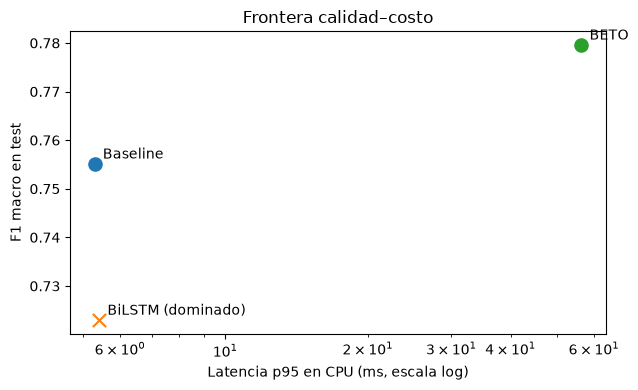

Supuestos: {'reseñas al mes': 20000, 'minutos de lectura por reseña': 1.5, 'auditoría aleatoria': 0.05}


,umbral (val),cobertura test,calidad de lo automatizado (test),reseñas a revisión al mes,horas-persona al mes,horas de cómputo al mes (CPU)
Baseline,0.56,0.887,0.901,3148.259,78.706,0.013
BiLSTM,0.66,0.842,0.892,4008.985,100.225,0.001
BETO,0.49,0.997,0.878,1049.794,26.245,0.174
Todo manual (hoy),NaN,NaN,NaN,20000.000,500.000,NaN


In [52]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for n, r in eficiencia.iterrows():
    dominado = any((o.f1_macro_test >= r.f1_macro_test) and (o.latencia_p95_ms <= r.latencia_p95_ms) and k != n for k, o in eficiencia.iterrows())
    ax.scatter(r.latencia_p95_ms, r.f1_macro_test, s=90, marker='x' if dominado else 'o')
    ax.annotate(f"{n}{' (dominado)' if dominado else ''}", (r.latencia_p95_ms, r.f1_macro_test), textcoords='offset points', xytext=(6, 4))
ax.set_xscale('log'); ax.set_xlabel('Latencia p95 en CPU (ms, escala log)'); ax.set_ylabel('F1 macro en test')
ax.set_title('Frontera calidad–costo'); plt.tight_layout(); plt.show()

# Carga humana mensual con la política de cada modelo (SUPUESTOS editables, no son datos de Bodytech)
SUPUESTOS = {'reseñas al mes': 20000, 'minutos de lectura por reseña': 1.5, 'auditoría aleatoria': .05}
carga = {}
for n, pn in [('Baseline', 'Baseline'), ('BiLSTM', 'BiLSTM'), ('BETO', 'BETO calibrado')]:
    th = elegir_umbral(va.etiqueta, P_VA[pn]); cob, cal = cobertura(te.etiqueta, P_TE[pn], th)
    revisadas = SUPUESTOS['reseñas al mes'] * ((1 - cob) + SUPUESTOS['auditoría aleatoria'] * cob)
    carga[n] = {'umbral (val)': th, 'cobertura test': cob, 'calidad de lo automatizado (test)': cal, 'reseñas a revisión al mes': revisadas,
                'horas-persona al mes': revisadas * SUPUESTOS['minutos de lectura por reseña'] / 60,
                'horas de cómputo al mes (CPU)': SUPUESTOS['reseñas al mes'] / eficiencia.loc[n, 'throughput_docs_s'] / 3600}
carga['Todo manual (hoy)'] = {'reseñas a revisión al mes': SUPUESTOS['reseñas al mes'],
                              'horas-persona al mes': SUPUESTOS['reseñas al mes'] * SUPUESTOS['minutos de lectura por reseña'] / 60}
print('Supuestos:', SUPUESTOS); display(pd.DataFrame(carga).T.round(3))

**Qué encontramos:**
- **Costo de BETO:** 110 M de parámetros (640 veces el baseline), 440 MB en disco, 350 MB de RAM y **latencia p95 de 41 a 56 ms en CPU** en dos mediciones con el equipo libre (56 ms en esta ejecución). Procesa unas 32 reseñas por segundo, frente a 425 del baseline. Entrenarlo exige GPU (22 min en un Apple M5).
- **La latencia depende de la carga del equipo:** medida mientras se entrenaba otro modelo, el p95 de BETO subió a 113 ms. En producción hay que medirla en el servidor real.
- **Ninguno es dominado:** BETO es el de mejor calidad y el más caro; el baseline y la BiLSTM son baratos, y el baseline tiene mejor calidad que la BiLSTM.
- **Carga humana (con los supuestos declarados de 20.000 reseñas al mes y 1,5 minutos por reseña):** hoy serían 500 horas-persona al mes. Con el baseline, **79 horas**; con BETO, 26 horas, pero solo porque su umbral casi no abstiene y su calidad automatizada queda en 0,878. Con un umbral recalibrado, BETO mandaría más reseñas a revisión.
- **El cómputo es despreciable:** menos de 0,2 horas de CPU al mes para BETO. El costo real está en las personas y en mantener el modelo.

## 13. Artefactos, registro de experimentos y reproducibilidad
Se guardan los modelos, la política de decisión (umbrales elegidos en validación), el registro de **todas** las corridas y el tablero final. Así la demo y cualquier auditoría usan exactamente lo que se evaluó.

In [53]:
from datetime import date
th_g = {n: float(elegir_umbral(va.etiqueta, P_VA[pn])) for n, pn in [('Baseline', 'Baseline'), ('BiLSTM', 'BiLSTM'), ('BETO', 'BETO calibrado')]}
politica = {
    'fecha': str(date.today()), 'semilla': SEED, 'clases': CLASES, 'clase_critica': CRIT, 'modelo_elegido': GANADOR,
    'modelos': {
        'Baseline': {'artefacto': ART['Baseline'], 'entrada': 'texto normalizado → lemas (spaCy es_core_news_sm)',
                     'umbral_abstencion': th_g['Baseline'], 't_negativa': float(T_NEG['Baseline'])},
        'BETO': {'artefacto': ART['BETO'], 'checkpoint_base': CKPT, 'max_length': L_BETO, 'temperatura': float(T_BETO),
                 'umbral_abstencion': th_g['BETO'], 't_negativa': float(T_NEG['BETO calibrado'])}},
    'filtros_previos': {'idioma': 'es_espanol(): ≥ 8 % de stopwords en español', 'texto_minimo_palabras': 3},
    'versiones': VERSIONES, 'hardware': HARDWARE,
}
json.dump(politica, open(MODELOS + 'politica.json', 'w'), indent=1, ensure_ascii=False)

def reg(d, familia, modelo, config, semilla='—', seg=None):
    d = d.copy(); d['familia'] = familia; d['modelo'] = modelo; d['config'] = config; d['semilla'] = d.get('semilla', semilla)
    if seg is not None: d['seg_entreno'] = seg
    return d
registro = pd.concat([
    reg(torneo.reset_index(), 'TF-IDF + LR', torneo.index.values, 'C=4, balanced', 'determinista'),
    reg(ab_res.reset_index().rename(columns={k: k + '_val' for k in ['f1_macro', 'recall_negativa', 'f1_neutra', 'log_loss']}),
        'TF-IDF + LR · A/B', ab_res.index.values, 'palabras 1-2', 'determinista'),
    reg(emb_res.reset_index(), 'Embedding promedio + LR', emb_res.index.values, '100 d, solo train', SEED),
    reg(semillas, 'RNN 7.1', semillas.modelo.values, f'SEQ_LEN {SEQ_LEN}, vocab {MAX_TOKENS}'),
    reg(largo, 'RNN 7.2', largo.modelo.values, 'SEQ_LEN ' + largo.SEQ_LEN.astype(str)),
    reg(emb_rnn, 'RNN 7.3', 'BiLSTM', emb_rnn.embedding.values),
    reg(pd.DataFrame([{**{k + '_val': v for k, v in metricas(va.etiqueta, softmax(lv)).items()},
                       **{k + '_test': v for k, v in metricas(te.etiqueta, softmax(lt)).items()},
                       'semilla': s, 'seg_entreno': meta['seg_entreno'], 'config': f"max_length {L}, lr 2e-5, batch 16, 3 épocas ({meta['dispositivo']})"}
                      for (L, s), (lv, lt, meta) in BETO.items()]), 'BETO fine-tuning', CKPT, None),
], ignore_index=True)
registro['config'] = registro['config'].fillna('')
cols = ['familia', 'modelo', 'config', 'semilla', 'f1_macro_val', 'recall_negativa_val', 'f1_neutra_val', 'log_loss_val',
        'f1_macro_test', 'recall_negativa_test', 'seg_entreno']
registro = registro[[c for c in cols if c in registro]].assign(**{f'v_{k}': v for k, v in VERSIONES.items() if k in ('sklearn', 'tensorflow', 'torch', 'transformers')},
                                                              hardware=HARDWARE['cpu'])
registro.to_csv(DOCS + 'registro_experimentos.csv', index=False)
print(f'Registro de experimentos: {len(registro)} corridas → {DOCS}registro_experimentos.csv')

with pd.ExcelWriter(ENTREGABLES + 'Tablero_Final.xlsx') as xw:
    tablero.join(eficiencia.drop(columns='f1_macro_test')).round(4).to_excel(xw, sheet_name='Tablero')
    candidatos.round(4).to_excel(xw, sheet_name='Selección (validación)')
    confirmacion.round(4).to_excel(xw, sheet_name='Validación vs test')
    regla.round(4).to_excel(xw, sheet_name='Regla negativas')
    segmentos_tab.round(4).to_excel(xw, sheet_name='Segmentos')
    rob_total.round(4).to_excel(xw, sheet_name='Robustez')
    registro.to_excel(xw, sheet_name='Registro', index=False)
arts = {'Baseline (joblib)': ART['Baseline'], 'BiLSTM (.keras)': ART['BiLSTM'], 'BETO (safetensors)': ART['BETO'],
        'Política (json)': MODELOS + 'politica.json', 'Partición (csv)': DATOS + 'particion.csv'}
display(pd.Series({k: f'{tamano_mb(v):,.2f} MB' for k, v in arts.items()}, name='tamaño').to_frame())
print(f'Tiempo total de esta ejecución: {(time.perf_counter() - T_INICIO) / 60:.1f} min · hardware: {HARDWARE}')

Registro de experimentos: 64 corridas → ../docs/registro_experimentos.csv


,tamaño
Baseline (joblib),2.80 MB
BiLSTM (.keras),16.20 MB
BETO (safetensors),440.17 MB
Política (json),0.00 MB
Partición (csv),0.54 MB


Tiempo total de esta ejecución: 8.6 min · hardware: {'sistema': 'macOS-26.5.2-arm64-arm-64bit', 'cpu': 'Apple M5', 'núcleos': 10, 'RAM (GB)': 25.8}


## 14. Criterio de adopción, gobierno y recomendación

In [54]:
pol = {'Baseline': 'Baseline', 'BiLSTM': 'BiLSTM', 'BETO': 'BETO calibrado'}
filas = []
for n in ['BiLSTM', 'BETO']:
    d_val = candidatos.loc[n, 'ΔF1 vs baseline']; d_test = tablero.loc[n, 'f1_macro'] - tablero.loc['Baseline', 'f1_macro']
    rec = regla.loc[f"{pol[n]} · regla", 'recall_negativa']; lat = eficiencia.loc[n, 'latencia_p95_ms']
    cob, cal = carga[n]['cobertura test'], carga[n]['calidad de lo automatizado (test)']
    filas.append({'modelo': n,
                  '1. ΔF1 ≥ +0,02 (val / test)': f"{'✓' if d_val >= .02 and d_test >= .02 else '✗'} {d_val:+.3f} / {d_test:+.3f}",
                  '2. Recall negativas ≥ 0,90 (regla)': f"{'✓' if rec >= .90 else '✗'} {rec:.3f}",
                  '3. Latencia p95 ≤ 150 ms (CPU)': f"{'✓' if lat <= 150 else '✗'} {lat:.1f} ms",
                  '   Prerregistro: ≤ 50 ms': f"{'✓' if lat <= 50 else '✗'}",
                  '4. Cobertura ≥ 75 % con calidad ≥ 0,90': f"{'✓' if cob >= .75 and cal >= .90 else '✗'} {cob:.1%} · calidad {cal:.3f}"})
rb, cb, qb = regla.loc['Baseline · regla', 'recall_negativa'], carga['Baseline']['cobertura test'], carga['Baseline']['calidad de lo automatizado (test)']
filas.append({'modelo': 'Baseline (referencia)', '1. ΔF1 ≥ +0,02 (val / test)': 'referencia',
              '2. Recall negativas ≥ 0,90 (regla)': f"{'✓' if rb >= .90 else '✗'} {rb:.3f}",
              '3. Latencia p95 ≤ 150 ms (CPU)': f"{'✓' if eficiencia.loc['Baseline', 'latencia_p95_ms'] <= 150 else '✗'} {eficiencia.loc['Baseline', 'latencia_p95_ms']:.1f} ms",
              '   Prerregistro: ≤ 50 ms': f"{'✓' if eficiencia.loc['Baseline', 'latencia_p95_ms'] <= 50 else '✗'}",
              '4. Cobertura ≥ 75 % con calidad ≥ 0,90': f"{'✓' if cb >= .75 and qb >= .90 else '✗'} {cb:.1%} · calidad {qb:.3f}"})
display(pd.DataFrame(filas).set_index('modelo'))

,"1. ΔF1 ≥ +0,02 (val / test)","2. Recall negativas ≥ 0,90 (regla)",3. Latencia p95 ≤ 150 ms (CPU),Prerregistro: ≤ 50 ms,"4. Cobertura ≥ 75 % con calidad ≥ 0,90"
modelo,,,,,
BiLSTM,✗ -0.023 / -0.032,✗ 0.874,✓ 5.4 ms,✓,✗ 84.2% · calidad 0.892
BETO,✓ +0.059 / +0.024,✗ 0.888,✓ 56.4 ms,✗,✗ 99.7% · calidad 0.878
Baseline (referencia),referencia,✗ 0.891,✓ 5.3 ms,✓,✓ 88.7% · calidad 0.901


### Lectura del criterio de adopción
- **BiLSTM:** no mejora al baseline (−0,032 en test). Se descarta.
- **BETO cumple 2 de 4:**
  - ✓ mejora el F1 macro (+0,059 en validación, +0,024 en test con la semilla 42 y +0,029 de media);
  - ✓ latencia ≤ 150 ms (56 ms; en el límite del prerregistro de 50 ms);
  - ✗ recall de negativas 0,888 con la regla;
  - ✗ calidad de lo automatizado 0,878.
- **El baseline tampoco cumple el recall de 0,90** (0,891). El límite de detección de quejas viene de los datos (≈ 40 % de los errores leídos son etiquetas ruidosas), no solo del modelo.

### Recomendación: **pilotear** (no adoptar todavía)
1. **En operación, el baseline TF-IDF de lemas**, con revisión humana: es el único que cumple la cobertura con calidad 0,901, responde en ≈ 5 ms, pesa 2,8 MB y es explicable (sección 4.2).
2. **BETO calibrado en *shadow mode***: clasifica en paralelo y registra lo que haría, pero no decide. Es el mejor modelo (F1 0,780 frente a 0,755, mejor clase neutra, menos falsas alarmas de queja), y **la complejidad adicional sí aporta valor**, pero todavía no con las garantías que exige el criterio.
3. **BETO pasa a operar solo si, en el piloto con reseñas reales de Bodytech, cumple los 4 criterios** durante 4 semanas: ΔF1 ≥ +0,02 sobre el baseline, recall de negativas auditado ≥ 0,90, p95 ≤ 150 ms en el servidor real y cobertura ≥ 75 % con calidad ≥ 0,90.

### Condiciones para el piloto
| Condición | Por qué |
|---|---|
| Reentrenar con 3.000 – 5.000 reseñas reales de Bodytech, misma partición por sede | El vocabulario de gimnasio no está en el corpus (8.1) |
| Detector de idioma y filtro de entradas absurdas antes del modelo | Errores en otro idioma con confianza 0,79 (11.2) |
| Normalizar textos en mayúsculas | BETO pierde 0,19 de F1 con mayúsculas (11.1) |
| Temperatura (T = 1,68) y umbral de abstención recalibrados con datos auditados | Validación fue optimista con BETO (9.2) |
| Regla P(negativa) ≥ t → coordinador de la sede; auditoría aleatoria del 5 % | El recall de negativas no llega a 0,90 en ningún modelo (9.4) |
| Probar `max_length` 256 y otro truncamiento (inicio + final) | 128 corta el 57 % de las negativas (8.1) |
| Auditar etiquetas de 3 ★ con una guía de anotación | 10 de 24 errores leídos son ruido de etiqueta (10) |

### Gobierno y operación
- **Dueño del modelo:** Gerencia IA (decide si se usa); Especialista ML (operación técnica); Ciencia de Datos (datos, etiquetas y monitoreo por sede).
- **Privacidad:** solo se procesa el texto de la reseña, sin datos personales del usuario; se enmascaran correos y URL; acceso por rol a las reseñas; retención limitada. **No se procesan:** datos de salud, documentos de identidad ni datos de pago (si aparecen, la reseña va a revisión y se enmascara).
- **Uso no previsto:** no evaluar empleados individuales con este modelo ni decidir sobre un usuario sin revisión humana.
- **Trazabilidad:** cada predicción guarda versión del modelo, umbrales (`modelos/politica.json`) y fecha.
- **Monitoreo semanal por sede y ciudad:** recall de negativas sobre la muestra auditada, % de abstención, distribución de clases, longitud, % de OOV y de otro idioma (*drift*).
- **Reentrenamiento:** cada trimestre o cuando el *drift* supere los umbrales de suspensión.
- **Criterio de suspensión** (todo vuelve a revisión manual y a la versión anterior):
  - recall de negativas auditado < 0,80 dos semanas seguidas, en total o en una sede con ≥ 30 reseñas;
  - abstención > 25 % u OOV > 8 %;
  - **una sola** queja grave no enrutada (lesión, seguridad, acoso o cobro indebido).

### Limitaciones
- **Corpus proxy:** reseñas hoteleras, no de gimnasio; ningún resultado se transfiere sin reentrenar.
- **Título:** sin título el F1 del baseline baja de 0,753 a 0,724 (A/B 4.1). Si las reseñas de Bodytech no lo traen, hay que esperar menos desempeño.
- **Ruido de etiqueta:** las estrellas no siempre coinciden con el texto.
- **Una sola partición por sede** y 3 semillas para BETO.
- **Reproducibilidad en GPU:** el entrenamiento en GPU no es idéntico bit a bit entre ejecuciones; por eso las corridas se guardan en `modelos/` y el notebook las reutiliza.
- **Latencia medida en un portátil** (Apple M5), no en el servidor de producción.

## Declaración de uso de IA generativa
- **Herramienta:** Claude (Anthropic), usado como asistente de código y redacción.
- **Finalidad:** estructurar el notebook, depurar código, proponer pruebas (semillas, validación frente a test, robustez) y redactar borradores de texto y presentación.
- **Verificación:** todas las cifras de este notebook salen de celdas ejecutadas; ninguna fue escrita a mano sin ejecutar. El equipo revisó el código, los resultados y las conclusiones, y es responsable de ellos.
- **Datos:** no se enviaron datos de Bodytech a servicios externos (no se usaron datos de Bodytech). El corpus es público y el entrenamiento fue local.